# Formula 1 Podium Prediction — Milestone 1

**Goal:** predict whether a driver finishes on the podium using information available after qualifying and before race start.

**Pipeline:** `14 raw CSVs` → `cleaned_dfs` → `results_dedup` → `modeling_results` → `feature_df` → `train / validation / test` → processed model matrices.

Read the notebook in order: **0 Setup → 1 Clean & audit → 2 EDA questions → 3 Feature engineering → 4 Feature selection & preprocessing → 5 Modeling (next).**

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


## 0. Setup and portable data loading

Run the notebook top-to-bottom. The loader works with `data/raw/` locally or a Kaggle dataset input.

> **How to read this notebook:** each main section names its owner, output, and hand-off. The code directly below each heading produces that section's evidence.

In [2]:
# Legacy Kaggle-only loader (kept for reference).
# It is intentionally commented out; use the portable loader in the next cell.
# df_circuits = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/circuits.csv')
# df_constructor_results = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_results.csv')
# df_constructor_standings = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_standings.csv')
# df_constructors = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructors.csv')
# df_driver_standings = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/driver_standings.csv')
# df_drivers = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/drivers.csv')
# df_lap_times = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/lap_times.csv')
# df_pit_stops = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/pit_stops.csv')
# df_qualifying = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/qualifying.csv')
# df_races = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/races.csv')
# df_results = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/results.csv')
# df_seasons = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/seasons.csv')
# df_sprint_results = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/sprint_results.csv')
# df_status = pd.read_csv('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/status.csv')

In [3]:
from pathlib import Path

# Works locally with data/raw/ and on Kaggle after the F1 dataset is added as an input.
DATA_DIR_CANDIDATES = [
    Path('/kaggle/input/formula-1-world-championship-1950-2020'),
    Path('/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020'),
    Path.cwd() / 'data' / 'raw',
    Path.cwd().parent / 'data' / 'raw',
]

DATA_DIR = next((path for path in DATA_DIR_CANDIDATES if (path / 'results.csv').is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        'Formula 1 CSV files not found. Extract the dataset into data/raw locally, '
        'or add the Formula 1 World Championship dataset as a Kaggle input.'
    )

DATA_FILES = {
    'circuits': 'circuits.csv',
    'constructor_results': 'constructor_results.csv',
    'constructor_standings': 'constructor_standings.csv',
    'constructors': 'constructors.csv',
    'driver_standings': 'driver_standings.csv',
    'drivers': 'drivers.csv',
    'lap_times': 'lap_times.csv',
    'pit_stops': 'pit_stops.csv',
    'qualifying': 'qualifying.csv',
    'races': 'races.csv',
    'results': 'results.csv',
    'seasons': 'seasons.csv',
    'sprint_results': 'sprint_results.csv',
    'status': 'status.csv',
}

missing_files = [filename for filename in DATA_FILES.values() if not (DATA_DIR / filename).is_file()]
if missing_files:
    raise FileNotFoundError(f'Missing required files in {DATA_DIR}: {missing_files}')

loaded_dfs = {name: pd.read_csv(DATA_DIR / filename) for name, filename in DATA_FILES.items()}
df_circuits = loaded_dfs['circuits']
df_constructor_results = loaded_dfs['constructor_results']
df_constructor_standings = loaded_dfs['constructor_standings']
df_constructors = loaded_dfs['constructors']
df_driver_standings = loaded_dfs['driver_standings']
df_drivers = loaded_dfs['drivers']
df_lap_times = loaded_dfs['lap_times']
df_pit_stops = loaded_dfs['pit_stops']
df_qualifying = loaded_dfs['qualifying']
df_races = loaded_dfs['races']
df_results = loaded_dfs['results']
df_seasons = loaded_dfs['seasons']
df_sprint_results = loaded_dfs['sprint_results']
df_status = loaded_dfs['status']

print(f'Loaded {len(loaded_dfs)} tables from: {DATA_DIR.resolve()}')

Loaded 14 tables from: C:\Users\noura\ML_F1_ACL2\data\raw


In [4]:
dfs = {
    "circuits": df_circuits,
    "constructor_results": df_constructor_results,
    "constructor_standings": df_constructor_standings,
    "constructors": df_constructors,
    "driver_standings": df_driver_standings,
    "drivers": df_drivers,
    "lap_times": df_lap_times,
    "pit_stops": df_pit_stops,
    "qualifying": df_qualifying,
    "races": df_races,
    "results": df_results,
    "seasons": df_seasons,
    "sprint_results": df_sprint_results,
    "status": df_status
}

# 1. Clean, audit, and create the modeling base — Member 1

> **Status: complete.** Output: `results_dedup` for the full audited history and `modeling_results` for race starters. Member 3 starts from `modeling_results`.

### 1.0 Initial Schema Inspection (`df.info()` for all 14 Tables)
We inspect the initial structure, column names, non-null counts, and data types across all 14 relational tables. Notice that dates, lap times, and numeric columns with sentinels are initially loaded as generic `object` strings.

In [5]:
for name, df in dfs.items():
    print(f"\n{'='*25} {name}.csv ({len(df):,} rows, {len(df.columns)} cols) {'='*25}")
    df.info(memory_usage="short")



========================= circuits.csv (77 rows, 9 cols) =========================
<class 'pandas.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     str    
 2   name        77 non-null     str    
 3   location    77 non-null     str    
 4   country     77 non-null     str    
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     str    
dtypes: float64(2), int64(2), str(5)
memory usage: 5.5 KB

========================= constructor_results.csv (12,625 rows, 5 cols) =========================
<class 'pandas.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorRe

### 1.1 Pre-Cleaning Audit: Literal Sentinel Occurrence (`\N`)
The raw Ergast database exports missing values as the literal string `\N`. Because Pandas loads these as strings (`object` dtype), standard `.isna()` checks miss them. We first audit sentinel occurrences across all 14 tables before cleaning.

In [6]:
audit_records = []
for name, df in dfs.items():
    sentinel_count = (df.astype(str) == r"\N").sum().sum()
    audit_records.append({
        "Table": f"{name}.csv",
        "Total Rows": len(df),
        "Total Columns": len(df.columns),
        r"'\N' Sentinels": sentinel_count
    })

audit_df = pd.DataFrame(audit_records).sort_values(r"'\N' Sentinels", ascending=False)
audit_df.reset_index(drop=True, inplace=True)
display(audit_df)

,Table,Total Rows,Total Columns,'\N' Sentinels
0,results.csv,26759,18,122887
1,constructor_results.csv,12625,5,12608
2,qualifying.csv,10494,9,11600
3,races.csv,1125,18,11349
4,drivers.csv,861,9,1559
5,sprint_results.csv,360,16,73
6,driver_standings.csv,34863,7,0
7,constructors.csv,212,5,0
8,constructor_standings.csv,13391,7,0
9,circuits.csv,77,9,0


> **Member 2 status: complete.** This early EDA checks class balance, grid patterns, season changes, and qualifying coverage. The required Q1–Q3 analyses appear in Section 2.

### 1.2 Initial EDA: Target Class Distribution & Sentinel Occurrences
Our target is predicting whether a driver finishes on the podium (`positionOrder <= 3`). In a modern 20-car grid, only 3 reach the podium (~15%), resulting in an overall historical base rate of ~12.8% (class imbalance).

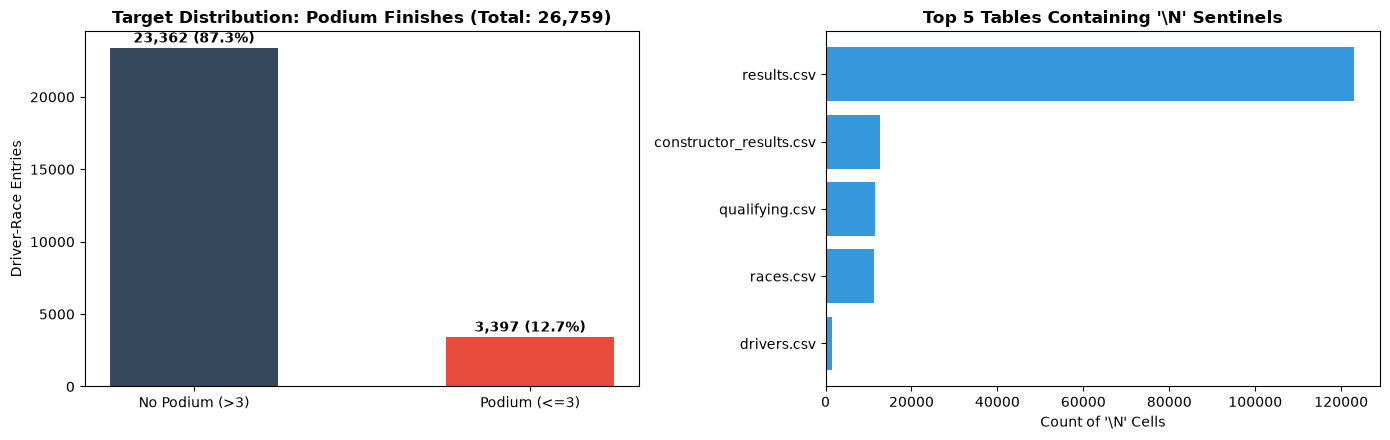

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

results_raw = dfs["results"].copy()
results_raw["target"] = (pd.to_numeric(results_raw["positionOrder"], errors="coerce") <= 3).map(
    {True: "Podium (<=3)", False: "No Podium (>3)"}
)
target_counts = results_raw["target"].value_counts()
axes[0].bar(target_counts.index, target_counts.values, color=["#34495e", "#e74c3c"], width=0.5)
axes[0].set_title(f"Target Distribution: Podium Finishes (Total: {len(results_raw):,})", fontweight="bold")
axes[0].set_ylabel("Driver-Race Entries")
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 400, f"{v:,} ({v/len(results_raw):.1%})", ha="center", fontweight="bold")

top_sentinels = audit_df[audit_df[r"'\N' Sentinels"] > 0].head(5)
axes[1].barh(top_sentinels["Table"], top_sentinels[r"'\N' Sentinels"], color="#3498db")
axes[1].set_title(r"Top 5 Tables Containing '\N' Sentinels", fontweight="bold")
axes[1].set_xlabel(r"Count of '\N' Cells")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

### 1.2.1 Domain Verification: Grid == 0 (Pit-Lane Starts vs. DNQ)
As noted in the F1 rules companion, a grid position of `0` in modern regulations represents a **pit-lane start** (e.g., penalty or parc-ferme engine change). In historical eras (1970s–1990s), `grid == 0` also designated non-qualifiers (DNQ/DNPQ) who did not earn a slot on the physical starting grid.

In [8]:
grid_zero = results_raw[pd.to_numeric(results_raw["grid"], errors="coerce") == 0]
print(f"Total entries with grid == 0: {len(grid_zero):,}")
print("\nTop status reasons for grid == 0:")
print(grid_zero.merge(dfs["status"], on="statusId")["status"].value_counts().head(5))

Total entries with grid == 0: 1,638

Top status reasons for grid == 0:
status
Did not qualify       1013
Did not prequalify     331
Withdrew               164
+1 Lap                  27
Finished                22
Name: count, dtype: int64


### 1.2.2 Starting Grid Distribution & Podium Conversion Rate (P1 to P10)
We examine the starting grid distribution and measure how frequently starting in top grid positions converts into a podium finish. Pole position (P1) converts into a podium ~64% of the time, dropping sharply past P6.

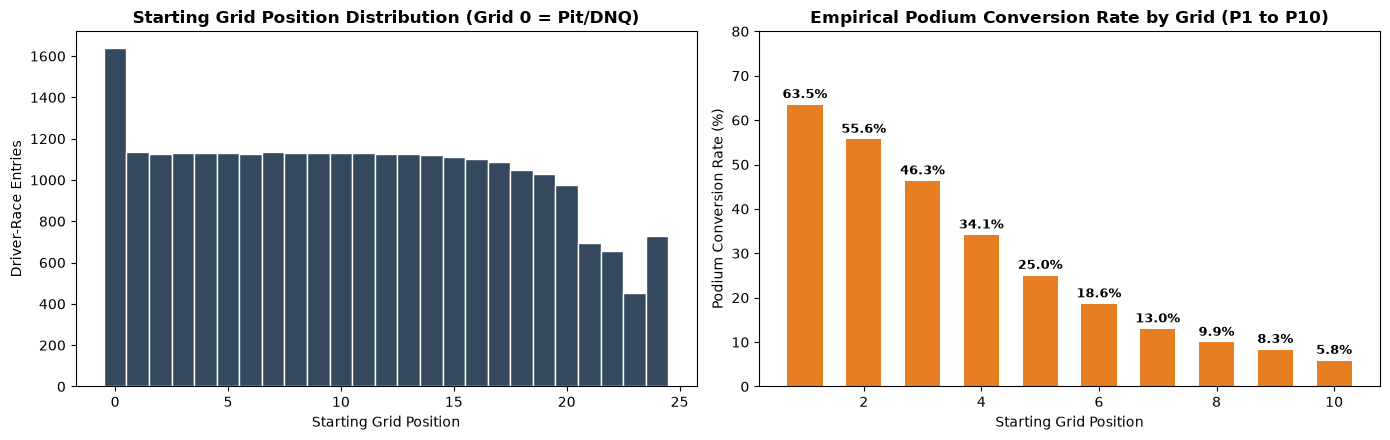

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
grid_num = pd.to_numeric(results_raw["grid"], errors="coerce")
pos_num = pd.to_numeric(results_raw["positionOrder"], errors="coerce")
podium_flag = (pos_num <= 3).astype(int)

axes[0].hist(grid_num.dropna(), bins=range(0, 26), color="#34495e", edgecolor="white", align="left")
axes[0].set_title("Starting Grid Position Distribution (Grid 0 = Pit/DNQ)", fontweight="bold")
axes[0].set_xlabel("Starting Grid Position")
axes[0].set_ylabel("Driver-Race Entries")

conv_df = pd.DataFrame({"grid": grid_num, "podium": podium_flag})
top10_conv = conv_df[conv_df["grid"].between(1, 10)].groupby("grid")["podium"].mean() * 100
axes[1].bar(top10_conv.index, top10_conv.values, color="#e67e22", width=0.6)
axes[1].set_title("Empirical Podium Conversion Rate by Grid (P1 to P10)", fontweight="bold")
axes[1].set_xlabel("Starting Grid Position")
axes[1].set_ylabel("Podium Conversion Rate (%)")
axes[1].set_ylim(0, 80)
for x, y in zip(top10_conv.index, top10_conv.values):
    axes[1].text(x, y + 1.5, f"{y:.1f}%", ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

### 1.2.3 Temporal Evolution: Calendar Expansion & Field Size Across Eras (1950–2024)
F1 evolved significantly: seasons grew from 7 races in 1950 to 24 in 2024. Meanwhile, field sizes shifted from oversubscribed 30+ car grids in the 1970s–1980s down to the strictly regulated 20-car grids of today.

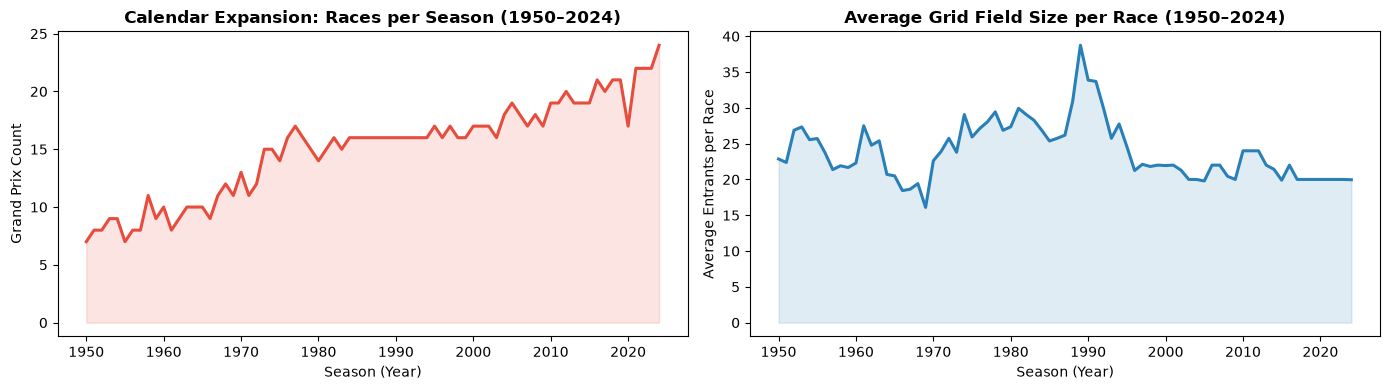

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
races_df = dfs["races"].copy()
races_df["year_num"] = pd.to_numeric(races_df["year"])
results_with_year = results_raw.merge(races_df[["raceId", "year_num"]], on="raceId")

races_per_year = races_df.groupby("year_num")["raceId"].count()
axes[0].plot(races_per_year.index, races_per_year.values, color="#e74c3c", lw=2.2)
axes[0].fill_between(races_per_year.index, races_per_year.values, color="#e74c3c", alpha=0.15)
axes[0].set_title("Calendar Expansion: Races per Season (1950–2024)", fontweight="bold")
axes[0].set_xlabel("Season (Year)")
axes[0].set_ylabel("Grand Prix Count")

field_size = results_with_year.groupby(["year_num", "raceId"]).size().groupby("year_num").mean()
axes[1].plot(field_size.index, field_size.values, color="#2980b9", lw=2.2)
axes[1].fill_between(field_size.index, field_size.values, color="#2980b9", alpha=0.15)
axes[1].set_title("Average Grid Field Size per Race (1950–2024)", fontweight="bold")
axes[1].set_xlabel("Season (Year)")
axes[1].set_ylabel("Average Entrants per Race")

plt.tight_layout()
plt.show()

### 1.3 Sentinel Replacement (`\N` $\rightarrow$ `np.nan`)
To preserve data integrity, raw tables remain immutable. We create a dictionary of working copies (`cleaned_dfs`) where all literal strings `\N` are replaced with `np.nan`.

In [11]:
cleaned_dfs = {}
for name, df in dfs.items():
    cleaned_dfs[name] = df.replace(r"\N", np.nan).copy()

total_sentinels_after = sum((df.astype(str) == r"\N").sum().sum() for df in cleaned_dfs.values())
print(f"Total sentinels remaining across all cleaned tables: {total_sentinels_after}")

Total sentinels remaining across all cleaned tables: 0


### 1.3.1 Impact of Cleaning: True Missingness Unmasked (Before vs. After)
Before sentinel cleaning, columns with literal `\N` strings reported 0% missingness under `.isna()`. Replacing sentinels unmasks the true missingness across post-race and telemetry fields.

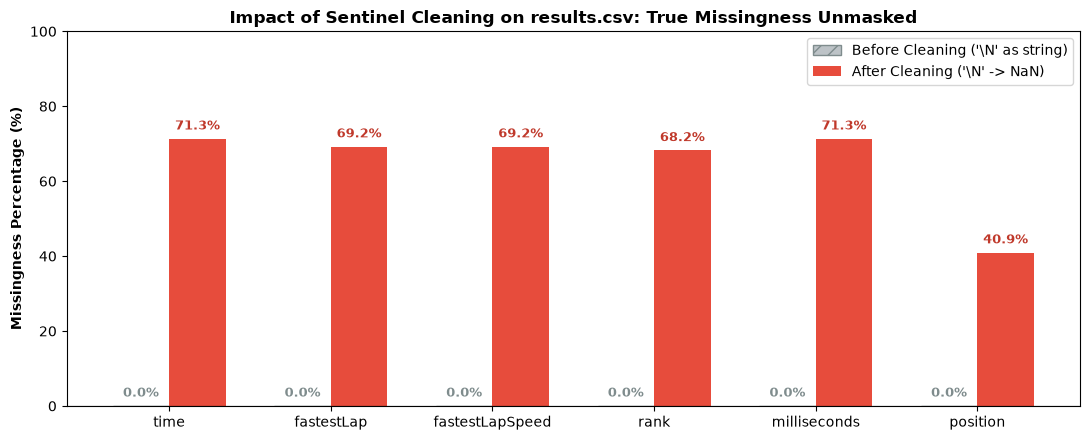

In [12]:
cols_to_compare = ["time", "fastestLap", "fastestLapSpeed", "rank", "milliseconds", "position"]
missing_before = (results_raw[cols_to_compare].isna().mean() * 100).round(1)
missing_after = (cleaned_dfs["results"][cols_to_compare].isna().mean() * 100).round(1)

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(cols_to_compare))
width = 0.35

ax.bar(x - width/2, missing_before, width, label=r"Before Cleaning ('\N' as string)", color="#bdc3c7", edgecolor="#7f8c8d", hatch="//")
ax.bar(x + width/2, missing_after, width, label=r"After Cleaning ('\N' -> NaN)", color="#e74c3c")
ax.set_title("Impact of Sentinel Cleaning on results.csv: True Missingness Unmasked", fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(cols_to_compare)
ax.set_ylabel("Missingness Percentage (%)", fontweight="bold")
ax.set_ylim(0, 100)
ax.axhline(0, color="black", lw=0.8)
ax.legend(frameon=True, loc="upper right")

for i in range(len(cols_to_compare)):
    ax.text(x[i] - width/2, 2.5, f"{missing_before.iloc[i]:.1f}%", ha="center", fontsize=9, fontweight="bold", color="#7f8c8d")
    ax.text(x[i] + width/2, missing_after.iloc[i] + 2.5, f"{missing_after.iloc[i]:.1f}%", ha="center", fontsize=9, fontweight="bold", color="#c0392b")

plt.tight_layout()
plt.show()


### 1.3.2 Column-Level Missingness Audit Across All Cleaned Tables

The plot above shows the before/after impact of sentinel replacement in `results.csv`. This audit extends the evidence to every cleaned table and reports every column that contains true missing values after `\N` has been converted to `NaN`.

,Table,Column,Missing count,Missing (%)
0,constructor_results.csv,status,12608,99.87
1,races.csv,sprint_time,1110,98.67
2,races.csv,sprint_date,1107,98.40
3,races.csv,fp3_time,1072,95.29
4,races.csv,fp1_time,1057,93.96
5,races.csv,fp2_time,1057,93.96
6,races.csv,quali_time,1057,93.96
7,races.csv,fp3_date,1053,93.60
8,drivers.csv,number,802,93.15
9,races.csv,fp1_date,1035,92.00


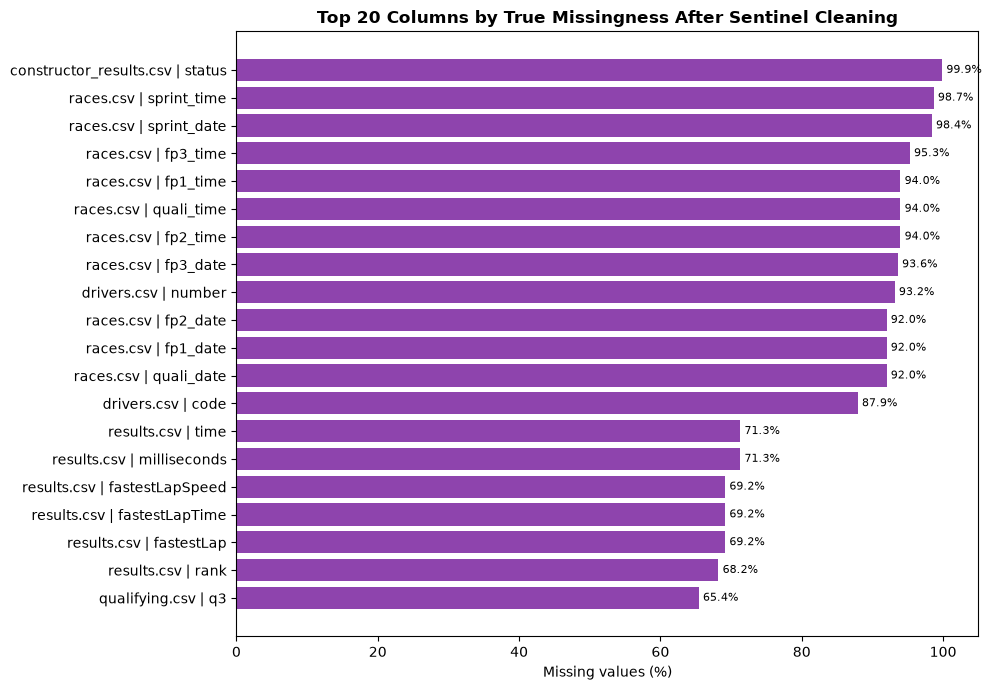

In [13]:
missingness_records = []
for table_name, frame in cleaned_dfs.items():
    null_counts = frame.isna().sum()
    for column, count in null_counts[null_counts.gt(0)].items():
        missingness_records.append({
            'Table': f'{table_name}.csv',
            'Column': column,
            'Missing count': int(count),
            'Missing (%)': round(count / len(frame) * 100, 2),
        })

all_table_missingness = (pd.DataFrame(missingness_records)
                         .sort_values(['Missing (%)', 'Table', 'Column'], ascending=[False, True, True])
                         .reset_index(drop=True))
display(all_table_missingness)

top_missing = all_table_missingness.head(20).sort_values('Missing (%)')
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_missing['Table'] + ' | ' + top_missing['Column'], top_missing['Missing (%)'], color='#8e44ad')
ax.set_title('Top 20 Columns by True Missingness After Sentinel Cleaning', fontweight='bold')
ax.set_xlabel('Missing values (%)')
for bar, value in zip(ax.patches, top_missing['Missing (%)']):
    ax.text(value + 0.6, bar.get_y() + bar.get_height() / 2, f'{value:.1f}%', va='center', fontsize=8)
ax.set_xlim(0, min(105, max(10, top_missing['Missing (%)'].max() + 8)))
plt.tight_layout()
plt.show()

### 1.4 Semantic Type Casting
We convert dates to `datetime64[ns]`, ordinals and positions to numeric types, and parse lap-time and pit-stop duration strings into numeric seconds.

In [14]:
def parse_lap_to_seconds(val):
    if pd.isna(val) or str(val).strip() == "":
        return np.nan
    try:
        val_str = str(val).strip()
        if ":" in val_str:
            parts = val_str.split(":")
            return float(parts[0]) * 60.0 + float(parts[1])
        return float(val_str)
    except Exception:
        return np.nan

cleaned_dfs["results"]["grid"] = pd.to_numeric(cleaned_dfs["results"]["grid"], errors="coerce")
cleaned_dfs["results"]["positionOrder"] = pd.to_numeric(cleaned_dfs["results"]["positionOrder"], errors="coerce")
cleaned_dfs["results"]["points"] = pd.to_numeric(cleaned_dfs["results"]["points"], errors="coerce").fillna(0.0)
cleaned_dfs["results"]["laps"] = pd.to_numeric(cleaned_dfs["results"]["laps"], errors="coerce")

cleaned_dfs["races"]["year"] = pd.to_numeric(cleaned_dfs["races"]["year"], errors="coerce")
cleaned_dfs["races"]["round"] = pd.to_numeric(cleaned_dfs["races"]["round"], errors="coerce")
cleaned_dfs["races"]["date"] = pd.to_datetime(cleaned_dfs["races"]["date"], errors="coerce")
cleaned_dfs["drivers"]["dob"] = pd.to_datetime(cleaned_dfs["drivers"]["dob"], errors="coerce")

cleaned_dfs["qualifying"]["position"] = pd.to_numeric(cleaned_dfs["qualifying"]["position"], errors="coerce")
for col in ["q1", "q2", "q3"]:
    cleaned_dfs["qualifying"][f"{col}_sec"] = cleaned_dfs["qualifying"][col].apply(parse_lap_to_seconds)
cleaned_dfs["pit_stops"]["duration_sec"] = pd.to_numeric(cleaned_dfs["pit_stops"]["duration"], errors="coerce")

print("Semantic type casting completed successfully.")

Semantic type casting completed successfully.


### 1.4.1 Complete Semantic Typing and Conversion Audit

The first casting cell handles the fields immediately needed for the base table. This follow-up converts remaining relevant dates and race-duration fields in the **cleaned copies only**. Post-race timing fields are retained for audit/analysis, but remain excluded from the later pre-race feature list.

In [15]:
def parse_duration_to_seconds(value):
    """Parse seconds, M:SS.xxx, or H:MM:SS.xxx safely into seconds."""
    if pd.isna(value) or str(value).strip() == '':
        return np.nan
    try:
        parts = [float(part) for part in str(value).strip().split(':')]
        if len(parts) == 1:
            return parts[0]
        if len(parts) == 2:
            return parts[0] * 60 + parts[1]
        if len(parts) == 3:
            return parts[0] * 3600 + parts[1] * 60 + parts[2]
    except (TypeError, ValueError):
        pass
    return np.nan

# Race-weekend dates are useful metadata even when not model inputs.
race_date_columns = ['date', 'fp1_date', 'fp2_date', 'fp3_date', 'quali_date', 'sprint_date']
for column in race_date_columns:
    cleaned_dfs['races'][column] = pd.to_datetime(cleaned_dfs['races'][column], errors='coerce')

# Convert race-duration strings into explicit seconds for auditable analysis.
cleaned_dfs['lap_times']['time_sec'] = cleaned_dfs['lap_times']['time'].apply(parse_duration_to_seconds)
cleaned_dfs['pit_stops']['time_sec'] = cleaned_dfs['pit_stops']['time'].apply(parse_duration_to_seconds)

# These results fields are post-race and are never selected as prediction features.
for column in ['milliseconds', 'fastestLap', 'rank', 'fastestLapSpeed']:
    cleaned_dfs['results'][column] = pd.to_numeric(cleaned_dfs['results'][column], errors='coerce')
cleaned_dfs['results']['fastestLapTime_sec'] = (
    cleaned_dfs['results']['fastestLapTime'].apply(parse_duration_to_seconds)
)

semantic_type_audit = pd.DataFrame([
    {'Table': 'races', 'Columns': ', '.join(race_date_columns), 'Rule': 'pd.to_datetime',
     'Cleaned dtype': 'datetime64'},
    {'Table': 'lap_times', 'Columns': 'time_sec', 'Rule': 'parse_duration_to_seconds',
     'Cleaned dtype': 'float seconds'},
    {'Table': 'pit_stops', 'Columns': 'duration_sec, time_sec', 'Rule': 'numeric/parse_duration_to_seconds',
     'Cleaned dtype': 'float seconds'},
    {'Table': 'results', 'Columns': 'milliseconds, fastestLap, rank, fastestLapSpeed, fastestLapTime_sec',
     'Rule': 'numeric/parse_duration_to_seconds', 'Cleaned dtype': 'numeric/float seconds'},
    {'Table': 'qualifying', 'Columns': 'q1_sec, q2_sec, q3_sec', 'Rule': 'parse_lap_to_seconds',
     'Cleaned dtype': 'float seconds'},
])
display(semantic_type_audit)

assert cleaned_dfs['lap_times']['time_sec'].notna().any(), 'Lap-time parsing produced no values.'
assert cleaned_dfs['pit_stops']['time_sec'].notna().any(), 'Pit-stop time parsing produced no values.'
print('Completed semantic typing audit; raw dfs remains unchanged.')

,Table,Columns,Rule,Cleaned dtype
0,races,"date, fp1_date, fp2_date, fp3_date, quali_date...",pd.to_datetime,datetime64
1,lap_times,time_sec,parse_duration_to_seconds,float seconds
2,pit_stops,"duration_sec, time_sec",numeric/parse_duration_to_seconds,float seconds
3,results,"milliseconds, fastestLap, rank, fastestLapSpee...",numeric/parse_duration_to_seconds,numeric/float seconds
4,qualifying,"q1_sec, q2_sec, q3_sec",parse_lap_to_seconds,float seconds


Completed semantic typing audit; raw dfs remains unchanged.


### 1.4.2 Detailed Type-Conversion Audit

This table records the raw source type and the resulting cleaned type for each converted or derived semantic field. It makes the type-conversion choices reviewable without modifying the raw `dfs` tables.

In [16]:
type_audit_spec = [
    ('results', 'grid', 'grid'), ('results', 'positionOrder', 'positionOrder'),
    ('results', 'points', 'points'), ('results', 'laps', 'laps'),
    ('results', 'milliseconds', 'milliseconds'), ('results', 'fastestLap', 'fastestLap'),
    ('results', 'rank', 'rank'), ('results', 'fastestLapSpeed', 'fastestLapSpeed'),
    ('results', 'fastestLapTime', 'fastestLapTime_sec'),
    ('races', 'year', 'year'), ('races', 'round', 'round'),
    ('races', 'date', 'date'), ('races', 'fp1_date', 'fp1_date'),
    ('races', 'fp2_date', 'fp2_date'), ('races', 'fp3_date', 'fp3_date'),
    ('races', 'quali_date', 'quali_date'), ('races', 'sprint_date', 'sprint_date'),
    ('drivers', 'dob', 'dob'), ('qualifying', 'position', 'position'),
    ('qualifying', 'q1', 'q1_sec'), ('qualifying', 'q2', 'q2_sec'),
    ('qualifying', 'q3', 'q3_sec'), ('lap_times', 'time', 'time_sec'),
    ('pit_stops', 'duration', 'duration_sec'), ('pit_stops', 'time', 'time_sec'),
]

detailed_type_audit = pd.DataFrame([
    {
        'Table': f'{table_name}.csv',
        'Source column': source_column,
        'Cleaned column': cleaned_column,
        'Raw dtype': str(dfs[table_name][source_column].dtype),
        'Cleaned dtype': str(cleaned_dfs[table_name][cleaned_column].dtype),
    }
    for table_name, source_column, cleaned_column in type_audit_spec
])
display(detailed_type_audit)
assert len(detailed_type_audit) == len(type_audit_spec)
print(f'Audited {len(detailed_type_audit)} semantic conversions; raw dfs remains unchanged.')

,Table,Source column,Cleaned column,Raw dtype,Cleaned dtype
0,results.csv,grid,grid,int64,int64
1,results.csv,positionOrder,positionOrder,int64,int64
2,results.csv,points,points,float64,float64
3,results.csv,laps,laps,int64,int64
4,results.csv,milliseconds,milliseconds,str,float64
5,results.csv,fastestLap,fastestLap,str,float64
6,results.csv,rank,rank,str,float64
7,results.csv,fastestLapSpeed,fastestLapSpeed,str,float64
8,results.csv,fastestLapTime,fastestLapTime_sec,str,float64
9,races.csv,year,year,int64,int64


Audited 25 semantic conversions; raw dfs remains unchanged.


### 1.5 Relational Integrity: Primary Key Verification
Primary keys must uniquely identify each row in a table and cannot contain null values. We programmatically verify this across all relational tables.

In [17]:
pk_definitions = {
    "circuits": "circuitId",
    "constructors": "constructorId",
    "constructor_results": "constructorResultsId",
    "constructor_standings": "constructorStandingsId",
    "drivers": "driverId",
    "driver_standings": "driverStandingsId",
    "qualifying": "qualifyId",
    "races": "raceId",
    "results": "resultId",
    "seasons": "year",
    "status": "statusId"
}

pk_all_pass = True
for tbl, pk in pk_definitions.items():
    s = cleaned_dfs[tbl][pk]
    is_unique = s.is_unique
    no_nulls = not s.isna().any()
    status = "PASS" if (is_unique and no_nulls) else "FAIL"
    if not (is_unique and no_nulls):
        pk_all_pass = False
    print(f"[{status}] {tbl}.{pk} (Unique: {is_unique}, Nulls: {s.isna().sum()})")

assert pk_all_pass, "Primary key integrity check failed!"

[PASS] circuits.circuitId (Unique: True, Nulls: 0)
[PASS] constructors.constructorId (Unique: True, Nulls: 0)
[PASS] constructor_results.constructorResultsId (Unique: True, Nulls: 0)
[PASS] constructor_standings.constructorStandingsId (Unique: True, Nulls: 0)
[PASS] drivers.driverId (Unique: True, Nulls: 0)
[PASS] driver_standings.driverStandingsId (Unique: True, Nulls: 0)
[PASS] qualifying.qualifyId (Unique: True, Nulls: 0)
[PASS] races.raceId (Unique: True, Nulls: 0)
[PASS] results.resultId (Unique: True, Nulls: 0)
[PASS] seasons.year (Unique: True, Nulls: 0)
[PASS] status.statusId (Unique: True, Nulls: 0)


### 1.5.1 Complete Primary-Key Verification for Event Tables

Some event-level tables do not have a single source identifier. We validate their documented composite keys so every record is uniquely addressable.

In [18]:
additional_pk_definitions = {
    'lap_times': ['raceId', 'driverId', 'lap'],
    'pit_stops': ['raceId', 'driverId', 'stop'],
    'sprint_results': ['resultId'],
}

additional_pk_all_pass = True
for table_name, key_columns in additional_pk_definitions.items():
    frame = cleaned_dfs[table_name]
    duplicate_count = int(frame.duplicated(subset=key_columns).sum())
    null_count = int(frame[key_columns].isna().sum().sum())
    is_valid = duplicate_count == 0 and null_count == 0
    status = 'PASS' if is_valid else 'FAIL'
    print(f'[{status}] {table_name}.{key_columns} (Duplicates: {duplicate_count}, Nulls: {null_count})')
    additional_pk_all_pass &= is_valid

assert additional_pk_all_pass, 'Additional primary-key integrity check failed!'

[PASS] lap_times.['raceId', 'driverId', 'lap'] (Duplicates: 0, Nulls: 0)
[PASS] pit_stops.['raceId', 'driverId', 'stop'] (Duplicates: 0, Nulls: 0)
[PASS] sprint_results.['resultId'] (Duplicates: 0, Nulls: 0)


### 1.6 Relational Integrity: Foreign Key Reconciliation
Every foreign key value in a child table must exist in the referenced parent table. We reconcile all key relational joins to guarantee that no orphan records exist.

In [19]:
fk_definitions = [
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),
    ("races", "circuitId", "circuits", "circuitId"),
    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),
    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),
    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId")
]

fk_all_pass = True
for child_tbl, child_fk, parent_tbl, parent_pk in fk_definitions:
    child_ids = cleaned_dfs[child_tbl][child_fk].dropna().unique()
    parent_ids = set(cleaned_dfs[parent_tbl][parent_pk].unique())
    orphans = set(child_ids) - parent_ids
    if len(orphans) == 0:
        print(f"[PASS] {child_tbl}.{child_fk} -> {parent_tbl}.{parent_pk}")
    else:
        print(f"[FAIL] {child_tbl}.{child_fk} -> {parent_tbl}.{parent_pk} ({len(orphans)} orphans)")
        fk_all_pass = False

assert fk_all_pass, "Foreign key reconciliation check failed!"

[PASS] results.raceId -> races.raceId
[PASS] results.driverId -> drivers.driverId
[PASS] results.constructorId -> constructors.constructorId
[PASS] results.statusId -> status.statusId
[PASS] races.circuitId -> circuits.circuitId
[PASS] qualifying.raceId -> races.raceId
[PASS] qualifying.driverId -> drivers.driverId
[PASS] qualifying.constructorId -> constructors.constructorId
[PASS] driver_standings.raceId -> races.raceId
[PASS] driver_standings.driverId -> drivers.driverId
[PASS] constructor_standings.raceId -> races.raceId
[PASS] constructor_standings.constructorId -> constructors.constructorId


### 1.6.1 Complete Foreign-Key Reconciliation for Remaining Tables

The earlier checks cover the primary modeling joins. This extension validates the remaining relational event tables and the race-to-season relationship.

In [20]:
additional_fk_definitions = [
    ('races', 'year', 'seasons', 'year'),
    ('constructor_results', 'raceId', 'races', 'raceId'),
    ('constructor_results', 'constructorId', 'constructors', 'constructorId'),
    ('lap_times', 'raceId', 'races', 'raceId'),
    ('lap_times', 'driverId', 'drivers', 'driverId'),
    ('pit_stops', 'raceId', 'races', 'raceId'),
    ('pit_stops', 'driverId', 'drivers', 'driverId'),
    ('sprint_results', 'raceId', 'races', 'raceId'),
    ('sprint_results', 'driverId', 'drivers', 'driverId'),
    ('sprint_results', 'constructorId', 'constructors', 'constructorId'),
    ('sprint_results', 'statusId', 'status', 'statusId'),
]

additional_fk_all_pass = True
for child_table, child_key, parent_table, parent_key in additional_fk_definitions:
    child_values = set(cleaned_dfs[child_table][child_key].dropna().unique())
    parent_values = set(cleaned_dfs[parent_table][parent_key].dropna().unique())
    orphan_count = len(child_values - parent_values)
    status = 'PASS' if orphan_count == 0 else 'FAIL'
    print(f'[{status}] {child_table}.{child_key} -> {parent_table}.{parent_key} (Orphans: {orphan_count})')
    additional_fk_all_pass &= orphan_count == 0

assert additional_fk_all_pass, 'Additional foreign-key reconciliation failed!'

[PASS] races.year -> seasons.year (Orphans: 0)
[PASS] constructor_results.raceId -> races.raceId (Orphans: 0)
[PASS] constructor_results.constructorId -> constructors.constructorId (Orphans: 0)
[PASS] lap_times.raceId -> races.raceId (Orphans: 0)
[PASS] lap_times.driverId -> drivers.driverId (Orphans: 0)
[PASS] pit_stops.raceId -> races.raceId (Orphans: 0)
[PASS] pit_stops.driverId -> drivers.driverId (Orphans: 0)
[PASS] sprint_results.raceId -> races.raceId (Orphans: 0)
[PASS] sprint_results.driverId -> drivers.driverId (Orphans: 0)
[PASS] sprint_results.constructorId -> constructors.constructorId (Orphans: 0)
[PASS] sprint_results.statusId -> status.statusId (Orphans: 0)


### 1.7 Enforcing Modeling Grain: Shared Drives (1950s Anomaly)
Our prediction unit is **one driver entering one race**: `(raceId, driverId)` must be strictly unique.
* **The Anomaly**: `results.csv` contains 176 duplicate rows for `(raceId, driverId)`.
* **Domain Explanation**: In early F1 (primarily 1950–1957), regulations permitted **shared drives**. If a star driver's car retired, they could take over a teammate's car mid-race, producing multiple result rows for that driver in a single race.

In [21]:
res = cleaned_dfs["results"].copy()
dup_mask = res.duplicated(subset=["raceId", "driverId"], keep=False)

print(f"Total rows in raw results: {len(res):,}")
print(f"Rows involved in duplicate (raceId, driverId): {dup_mask.sum():,}")

dup_races = res[dup_mask].merge(cleaned_dfs["races"][["raceId", "year"]], on="raceId")
dup_decade_counts = (dup_races["year"] // 10 * 10).value_counts().sort_index().rename(lambda y: f"{y}s")
print("\nShared drive duplicates by decade:")
print(dup_decade_counts)

Total rows in raw results: 26,759
Rows involved in duplicate (raceId, driverId): 176

Shared drive duplicates by decade:
year
1950s    164
1960s     10
1970s      2
Name: count, dtype: int64


### 1.7.1 Visualization: Shared Drive Duplicates Across Eras
We visualize the chronological distribution of shared-drive duplicates. Over 93% (164 of 176) occurred in the 1950s, confirming they represent historical regulations rather than modern telemetry bugs.

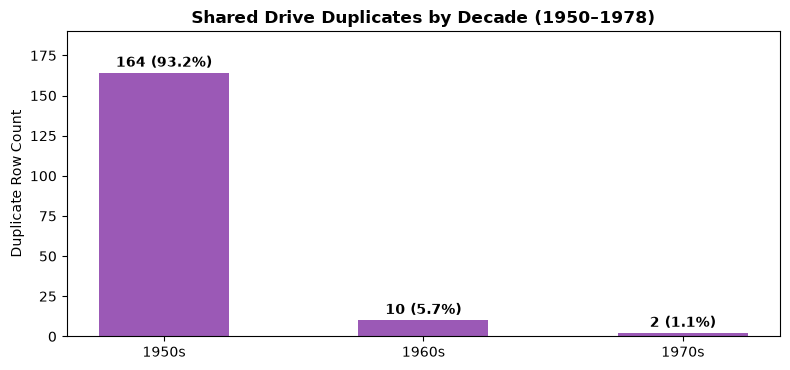

In [22]:
fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(dup_decade_counts.index, dup_decade_counts.values, color="#9b59b6", width=0.5)
ax.set_title("Shared Drive Duplicates by Decade (1950–1978)", fontweight="bold")
ax.set_ylabel("Duplicate Row Count")
ax.set_ylim(0, 190)
for bar in bars:
    y = bar.get_height()
    pct = y / dup_decade_counts.sum() * 100
    ax.text(bar.get_x() + bar.get_width()/2, y + 4, f"{y} ({pct:.1f}%)", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

### 1.8 Deduplication Rule & Verification
**Rule Choice & Domain Justification**:
1. Priority 1: Retain the car the driver **started the race in** (`grid > 0`). Our model makes pre-race predictions based on grid positions before lights out.
2. Priority 2: If both records have grid positions (or neither), retain the car with the superior finishing position (lower `positionOrder`).

In [23]:
res["started_car"] = (res["grid"] > 0).astype(int)

results_dedup = res.sort_values(
    by=["raceId", "driverId", "started_car", "positionOrder"],
    ascending=[True, True, False, True]
).drop_duplicates(subset=["raceId", "driverId"], keep="first").drop(columns=["started_car"]).copy()

print(f"Cleaned unique modeling table rows: {len(results_dedup):,}")
assert not results_dedup.duplicated(subset=["raceId", "driverId"]).any(), "Grain violation detected!"
print("[PASS] Modeling grain verified: Exactly 1 row per (raceId, driverId).")

Cleaned unique modeling table rows: 26,668
[PASS] Modeling grain verified: Exactly 1 row per (raceId, driverId).


### 1.8.1 Historical Edge Cases: Indianapolis 500 & Non-Qualifiers (DNQ)
We audit two historical F1 domain anomalies noted in the project companion:
1. **The Indianapolis 500 (1950–1960)**: 11 races included in the World Championship calendar that were run under USAC oval rules by American drivers who rarely competed in European F1. We audit these 11 races.
2. **Non-Qualifiers (DNQ/DNPQ)**: In oversubscribed eras (1980s–1990s), drivers who failed to qualify never took the race start (`grid == 0`). We verify that exactly 0 of these 1,356 entries ever scored a podium finish.

In [24]:
indy_races = cleaned_dfs["races"][cleaned_dfs["races"]["name"].str.contains("Indianapolis 500", case=False, na=False)]
print(f"Total Indianapolis 500 races (1950–1960): {len(indy_races)}")

dnq_status_ids = cleaned_dfs["status"][cleaned_dfs["status"]["status"].str.contains("qualify", case=False, na=False)]["statusId"]
dnq_entries = results_dedup[results_dedup["statusId"].isin(dnq_status_ids)]
print(f"Total DNQ/DNPQ entries in results: {len(dnq_entries):,}")
print(f"Podium finishes among non-qualifiers (must be 0): {(dnq_entries['positionOrder'] <= 3).sum()}")


Total Indianapolis 500 races (1950–1960): 11
Total DNQ/DNPQ entries in results: 1,354
Podium finishes among non-qualifiers (must be 0): 0


### 1.8.2 Final Historical-Population Policy

**Audited base:** `results_dedup` retains every official result record after shared-drive resolution, preserving historical completeness for auditing and descriptive analysis.

**Modeling base:** `modeling_results` excludes only confirmed non-starters: `Did not qualify`, `Did not prequalify`, and `Withdrew`. They cannot finish a race and should not become trivially negative podium examples. A `grid == 0` value alone does **not** cause exclusion because it can represent a legitimate pit-lane start.

**Indianapolis 500:** retain its 11 official 1950-1960 championship races in both bases, but flag them for sensitivity analysis because their field and competition context differ from other F1 rounds.

In [25]:
status_labels = cleaned_dfs['status'][['statusId', 'status']].copy()
population_audit = results_dedup.merge(status_labels, on='statusId', how='left', validate='many_to_one')
non_starter_statuses = {'Did not qualify', 'Did not prequalify', 'Withdrew'}
population_audit['is_non_starter'] = population_audit['status'].isin(non_starter_statuses)

indy_race_ids = set(indy_races['raceId'])
population_audit['is_indianapolis_500'] = population_audit['raceId'].isin(indy_race_ids)
modeling_results = population_audit.loc[~population_audit['is_non_starter']].drop(columns=['status', 'is_non_starter']).copy()

assert not modeling_results.duplicated(['raceId', 'driverId']).any()
assert len(modeling_results) + int(population_audit['is_non_starter'].sum()) == len(results_dedup)
print(f'Audited historical base rows: {len(results_dedup):,}')
print(f'Excluded confirmed non-starters: {int(population_audit["is_non_starter"].sum()):,}')
print(f'Race-starter modeling rows: {len(modeling_results):,}')
print(f'Indianapolis 500 rows retained and flagged: {int(modeling_results["is_indianapolis_500"].sum()):,}')

Audited historical base rows: 26,668
Excluded confirmed non-starters: 1,601
Race-starter modeling rows: 25,067
Indianapolis 500 rows retained and flagged: 381


### 1.9 Post-Cleaning EDA: Historical Qualifying Coverage Drift
The `qualifying.csv` table records detailed knockout times only from 1994 onwards (0% coverage before 1994). This empirical finding proves that our modeling pipeline must use `results.grid` as the primary pre-race starting position to avoid dropping historical races.

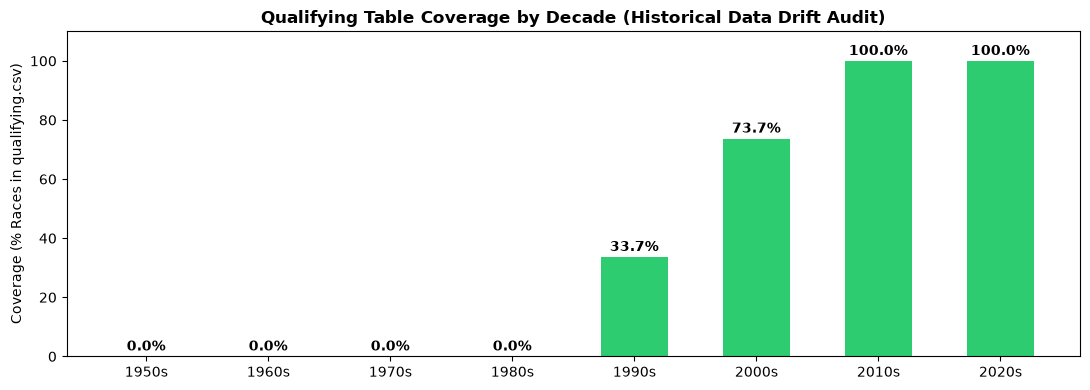

Audit Insight: qualifying.csv coverage is 0% before 1994.
Conclusion: Fallback to results.grid is mandatory for historical data integrity.


In [26]:
audit_races = results_dedup.merge(cleaned_dfs["races"][["raceId", "year"]], on="raceId")
qual_race_ids = set(cleaned_dfs["qualifying"]["raceId"].unique())
audit_races["has_qualifying"] = audit_races["raceId"].isin(qual_race_ids)

coverage = audit_races.groupby((audit_races["year"] // 10) * 10)["has_qualifying"].agg(["count", "mean"]).reset_index()
coverage["decade"] = coverage["year"].astype(str) + "s"

fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.bar(coverage["decade"], coverage["mean"] * 100, color="#2ecc71", width=0.55)
ax.set_title("Qualifying Table Coverage by Decade (Historical Data Drift Audit)", fontweight="bold")
ax.set_ylabel("Coverage (% Races in qualifying.csv)")
ax.set_ylim(0, 110)
for bar in bars:
    y = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, y + 2, f"{y:.1f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

print("Audit Insight: qualifying.csv coverage is 0% before 1994.")
print("Conclusion: Fallback to results.grid is mandatory for historical data integrity.")

---
# 2. EDA and required data questions — Member 2

> **Status: complete.** Q1 studies front-row conversion, Q2 tests home advantage after controlling for grid, and Q3 compares constructor mechanical-retirement rates. These are descriptive analyses only; current-race outcomes never become prediction features.

## Q1. Front-row starts that become podiums

**Data:** `results_dedup` → `races` → `circuits`; qualifying is joined only to compare it with actual grid. One row remains one driver-race. Front row means `grid` 1–2, and missing qualifying rows stay because grid is the broadly available pre-race field. This complete deduplicated historical base is used for descriptive analysis.

**Method:** rank circuits with at least 10 front-row starts, comparing pre-2014 with 2014 onward. **Result:** Magny-Cours leads before 2014 (80.6%, 29/36); Suzuka leads from 2014 onward (88.9%, 16/18). These are descriptive rates, not causal effects.

Q1 grain: 26,668 unique driver-race rows; 2,243 actual front-row starts.
Qualifying position is available for 39.4% of deduplicated result rows; among available rows, actual grid differs from qualifying position 23.9% of the time.
Ranking rule: at least 10 front-row starts per circuit-era.


,era,rank_within_era,circuit_label,front_row_starts,podiums,podium_conversion_rate
17,2014-2024 hybrid era,1,Suzuka Circuit (Japan),18,16,0.888889
18,2014-2024 hybrid era,2,Yas Marina Circuit (UAE),22,19,0.863636
5,2014-2024 hybrid era,3,Circuit de Monaco (Monaco),20,17,0.850000
3,2014-2024 hybrid era,4,Circuit de Barcelona-Catalunya (Spain),22,18,0.818182
10,2014-2024 hybrid era,4,Circuit de Spa-Francorchamps (Belgium),22,18,0.818182
...,...,...,...,...,...,...
60,Pre-2014,33,Kyalami (South Africa),40,17,0.425000
77,Pre-2014,34,Scandinavian Raceway (Sweden),12,5,0.416667
68,Pre-2014,35,Brands Hatch (UK),28,11,0.392857
66,Pre-2014,36,Autódromo Internacional Nelson Piquet (Brazil),20,7,0.350000


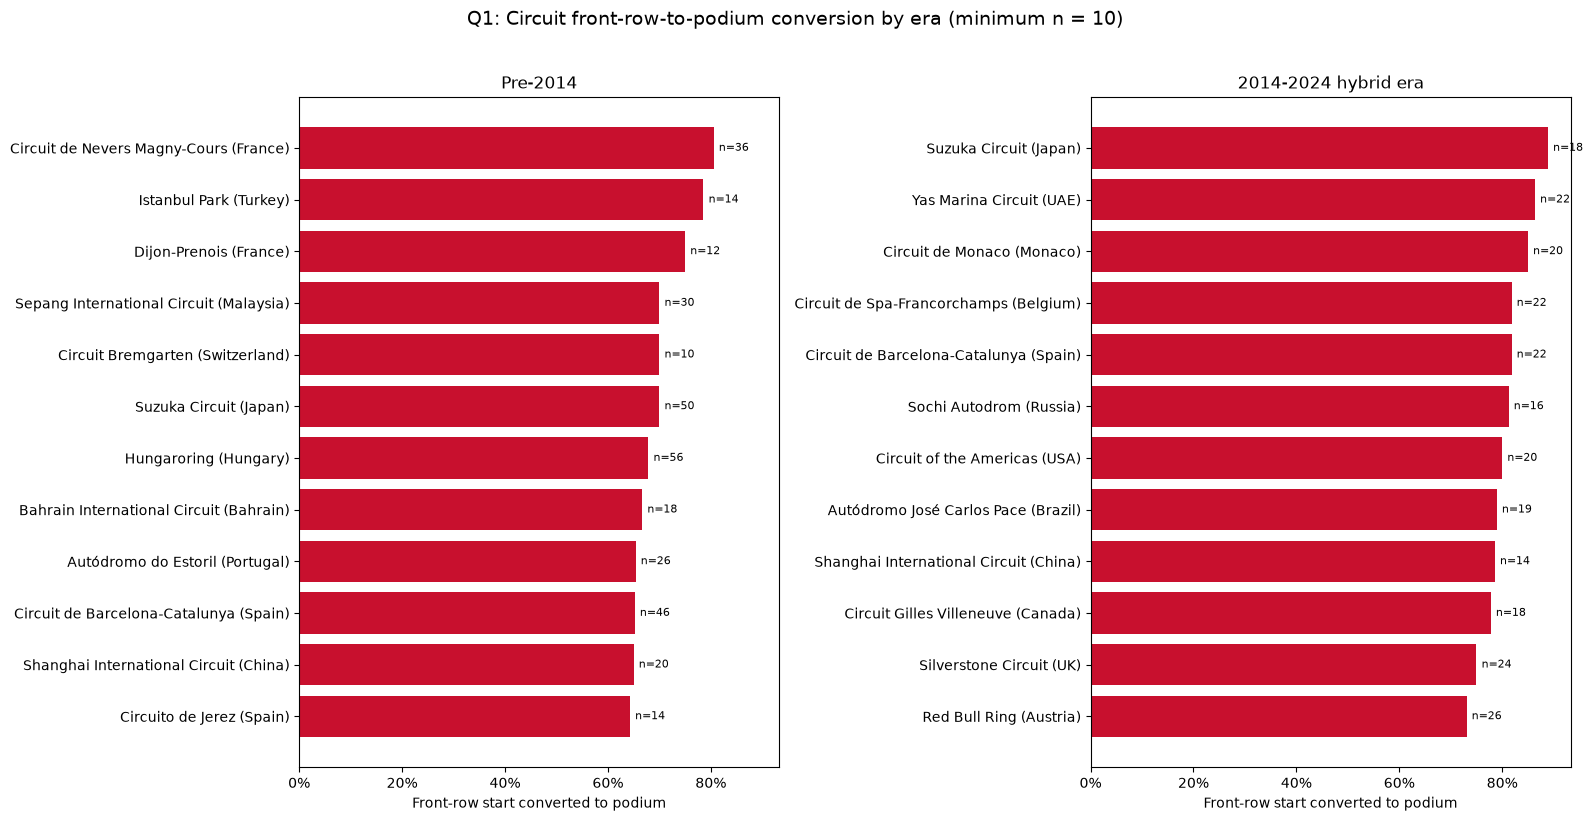

2014-2024 hybrid era: Suzuka Circuit (Japan) ranks first at 88.9% (16/18 front-row starts).
Pre-2014: Circuit de Nevers Magny-Cours (France) ranks first at 80.6% (29/36 front-row starts).
Limitation: circuit estimates may reflect driver/constructor strength and changing calendars, not a causal circuit effect.


In [27]:
# Q1: circuits that convert actual front-row grid starts into podiums
assert 'modeling_results' in globals() and 'cleaned_dfs' in globals(), 'Run Member 1 cells first.'

q1_races = cleaned_dfs['races'][['raceId', 'year', 'circuitId']].copy()
q1_circuits = cleaned_dfs['circuits'][['circuitId', 'name', 'country']].rename(
    columns={'name': 'circuit_name', 'country': 'circuit_country'}
)
q1_qualifying = cleaned_dfs['qualifying'][['raceId', 'driverId', 'position']].copy()
q1_qualifying['qualifying_position'] = pd.to_numeric(q1_qualifying['position'], errors='coerce')
q1_qualifying = q1_qualifying.drop(columns='position')
assert not q1_qualifying.duplicated(['raceId', 'driverId']).any(), 'Qualifying join is not one row per driver-race.'

q1 = (results_dedup
      .merge(q1_races, on='raceId', how='left', validate='many_to_one')
      .merge(q1_circuits, on='circuitId', how='left', validate='many_to_one')
      .merge(q1_qualifying, on=['raceId', 'driverId'], how='left', validate='one_to_one'))
assert not q1.duplicated(['raceId', 'driverId']).any()
q1['grid'] = pd.to_numeric(q1['grid'], errors='coerce')
q1['podium'] = (pd.to_numeric(q1['positionOrder'], errors='raise') <= 3).astype(int)
q1['era'] = np.where(q1['year'] < 2014, 'Pre-2014', '2014-2024 hybrid era')
q1['front_row_grid'] = q1['grid'].isin([1, 2])
q1['front_row_qualifying'] = q1['qualifying_position'].isin([1, 2])
q1['circuit_label'] = q1['circuit_name'] + ' (' + q1['circuit_country'] + ')'

q1_front_row = q1.loc[q1['front_row_grid']].copy()
q1_conversion_all = (q1_front_row.groupby(['era', 'circuitId', 'circuit_label'], as_index=False)
                     .agg(front_row_starts=('podium', 'size'), podiums=('podium', 'sum')))
q1_conversion_all['podium_conversion_rate'] = q1_conversion_all['podiums'] / q1_conversion_all['front_row_starts']
MIN_FRONT_ROW_STARTS = 10
q1_ranking = (q1_conversion_all.loc[lambda d: d['front_row_starts'] >= MIN_FRONT_ROW_STARTS]
              .sort_values(['era', 'podium_conversion_rate', 'front_row_starts'], ascending=[True, False, False])
              .copy())
q1_ranking['rank_within_era'] = q1_ranking.groupby('era')['podium_conversion_rate'].rank(
    method='dense', ascending=False
).astype(int)

qualifying_coverage = q1['qualifying_position'].notna().mean()
q1_grid_qualifying_audit = (q1.loc[q1['qualifying_position'].notna()]
                            .assign(grid_differs_from_qualifying=lambda d: d['grid'] != d['qualifying_position'])
                            [['raceId', 'driverId', 'year', 'grid', 'qualifying_position',
                              'front_row_grid', 'front_row_qualifying', 'grid_differs_from_qualifying']])
grid_qualifying_difference_rate = q1_grid_qualifying_audit['grid_differs_from_qualifying'].mean()

print(f'Q1 grain: {len(q1):,} unique driver-race rows; {len(q1_front_row):,} actual front-row starts.')
print(f'Qualifying position is available for {qualifying_coverage:.1%} of deduplicated result rows; among available rows, '
      f'actual grid differs from qualifying position {grid_qualifying_difference_rate:.1%} of the time.')
print(f'Ranking rule: at least {MIN_FRONT_ROW_STARTS} front-row starts per circuit-era.')
display(q1_ranking[['era', 'rank_within_era', 'circuit_label', 'front_row_starts', 'podiums',
                    'podium_conversion_rate']].sort_values(['era', 'rank_within_era', 'circuit_label']))

fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=True)
for ax, era in zip(axes, ['Pre-2014', '2014-2024 hybrid era']):
    chart = q1_ranking.loc[q1_ranking['era'].eq(era)].nlargest(12, 'podium_conversion_rate').sort_values('podium_conversion_rate')
    ax.barh(chart['circuit_label'], chart['podium_conversion_rate'], color='#c8102e')
    ax.set_title(era)
    ax.set_xlabel('Front-row start converted to podium')
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    for y, (_, row) in enumerate(chart.iterrows()):
        ax.text(row['podium_conversion_rate'] + 0.01, y, f"n={int(row['front_row_starts'])}", va='center', fontsize=8)
fig.suptitle('Q1: Circuit front-row-to-podium conversion by era (minimum n = 10)', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

q1_leaders = (q1_ranking.sort_values(['era', 'podium_conversion_rate', 'front_row_starts'], ascending=[True, False, False])
              .groupby('era', as_index=False).first())
for _, row in q1_leaders.iterrows():
    print(f"{row['era']}: {row['circuit_label']} ranks first at {row['podium_conversion_rate']:.1%} "
          f"({int(row['podiums'])}/{int(row['front_row_starts'])} front-row starts).")
print('Limitation: circuit estimates may reflect driver/constructor strength and changing calendars, not a causal circuit effect.')


## Q2. Home-race podiums, controlled for grid

**Data:** `results_dedup` → `races` → `circuits` → `drivers`. A home race uses the driver's recorded nationality and the circuit country (the explicit mapping is in the code).

**Method:** exclude `grid == 0`, retain and flag Indianapolis 500 rows because they are official championship records, compare home/away drivers within every positive grid position, then use a within-grid permutation test. **Result:** the standardized difference is −0.25 percentage points (`p = 0.7201`), so this dataset shows no evidence of a home-race podium advantage after grid is controlled.

Q2 grain before exclusions: 26,668 unique driver-race rows.
Excluded 1,635 grid==0 rows and 0 rows with an unmapped nationality.
Indianapolis 500 policy: retained 381 official-result rows; interpret this historical subset cautiously.
Grid-controlled sample: 25,033 rows; 2,319 home-race entries.
Standardized home minus away podium rate: -0.25%; within-grid permutation p-value: 0.7201.
Unmapped nationalities: none


,grid,starts_home,starts_away,podium_rate_home,podium_rate_away,home_minus_away
0,1,92.0,1032.0,0.576087,0.647287,-0.071200
1,2,87.0,1032.0,0.528736,0.562016,-0.033280
2,3,85.0,1042.0,0.541176,0.457774,0.083403
3,4,85.0,1043.0,0.317647,0.344199,-0.026552
4,5,82.0,1039.0,0.304878,0.246391,0.058487
5,6,94.0,1026.0,0.127660,0.192008,-0.064348
6,7,90.0,1042.0,0.166667,0.126679,0.039987
7,8,90.0,1032.0,0.066667,0.102713,-0.036047
8,9,109.0,1023.0,0.091743,0.082111,0.009632
9,10,99.0,1026.0,0.030303,0.061404,-0.031100


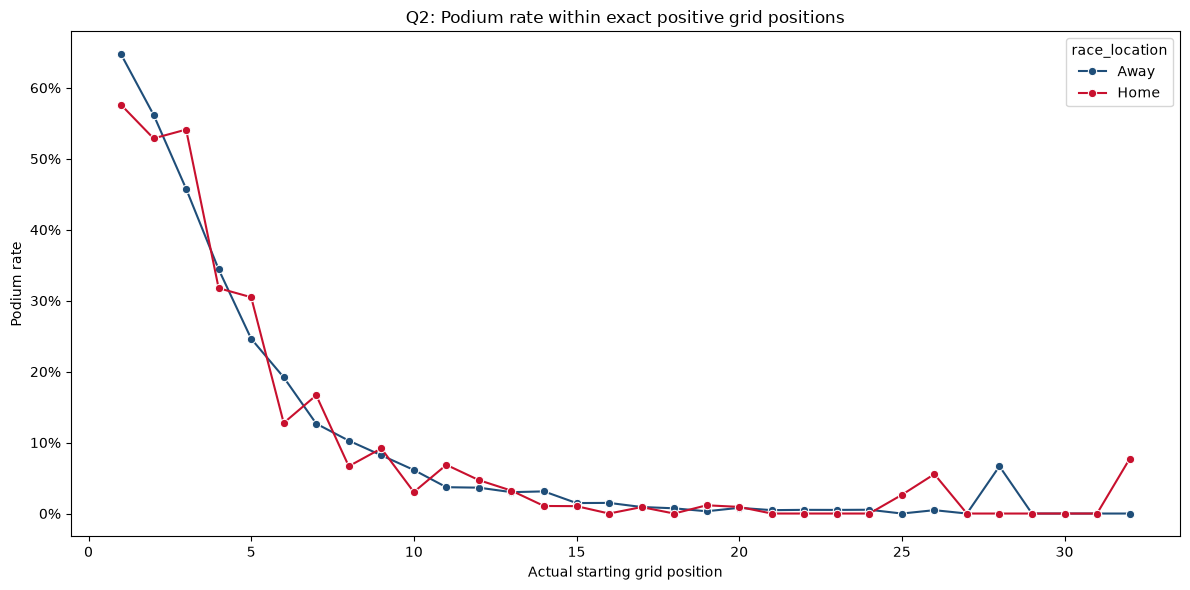

Interpretation: this is an adjusted association, not evidence that racing at home causes a podium finish.


In [28]:
# Q2: home-race podium association after controlling for exact actual grid position
NATIONALITY_TO_HOME_KEYS = {
    'American': {'usa'}, 'American-Italian': {'usa', 'italy'}, 'Argentine': {'argentina'},
    'Argentine-Italian': {'argentina', 'italy'}, 'Argentinian': {'argentina'}, 'Australian': {'australia'},
    'Austrian': {'austria'}, 'Belgian': {'belgium'}, 'Brazilian': {'brazil'}, 'British': {'uk'},
    'Canadian': {'canada'}, 'Chilean': {'chile'}, 'Chinese': {'china'}, 'Colombian': {'colombia'},
    'Czech': {'czech republic'}, 'Danish': {'denmark'}, 'Dutch': {'netherlands'},
    'East German': {'east germany'}, 'Finnish': {'finland'}, 'French': {'france'}, 'German': {'germany'},
    'Hungarian': {'hungary'}, 'Indian': {'india'}, 'Indonesian': {'indonesia'}, 'Irish': {'ireland'},
    'Italian': {'italy'}, 'Japanese': {'japan'}, 'Liechtensteiner': {'liechtenstein'},
    'Malaysian': {'malaysia'}, 'Mexican': {'mexico'}, 'Monegasque': {'monaco'},
    'New Zealander': {'new zealand'}, 'Polish': {'poland'}, 'Portuguese': {'portugal'},
    'Rhodesian': {'rhodesia'}, 'Russian': {'russia'}, 'South African': {'south africa'},
    'Spanish': {'spain'}, 'Swedish': {'sweden'}, 'Swiss': {'switzerland'}, 'Thai': {'thailand'},
    'Uruguayan': {'uruguay'}, 'Venezuelan': {'venezuela'},
}
CIRCUIT_COUNTRY_TO_KEY = {'USA': 'usa', 'United States': 'usa', 'UK': 'uk', 'UAE': 'united arab emirates'}

# Use the complete deduplicated historical base for this descriptive analysis.
q2 = (results_dedup
      .merge(cleaned_dfs['races'][['raceId', 'circuitId', 'year', 'name']], on='raceId', how='left', validate='many_to_one')
      .merge(cleaned_dfs['circuits'][['circuitId', 'country']], on='circuitId', how='left', validate='many_to_one')
      .merge(cleaned_dfs['drivers'][['driverId', 'nationality']], on='driverId', how='left', validate='many_to_one'))
assert not q2.duplicated(['raceId', 'driverId']).any()
# Retain Indianapolis 500 rows because they are official championship records; flag them for interpretation.
q2['is_indianapolis_500'] = q2['name'].str.contains('Indianapolis 500', case=False, na=False)
q2['grid'] = pd.to_numeric(q2['grid'], errors='coerce')
q2['podium'] = (pd.to_numeric(q2['positionOrder'], errors='raise') <= 3).astype(int)
q2['nationality_clean'] = q2['nationality'].astype('string').str.strip()
q2['circuit_country_key'] = q2['country'].map(CIRCUIT_COUNTRY_TO_KEY).fillna(
    q2['country'].astype('string').str.strip().str.lower()
)
q2['home_country_keys'] = q2['nationality_clean'].map(NATIONALITY_TO_HOME_KEYS)
q2['nationality_mapped'] = q2['home_country_keys'].notna()
q2['is_home'] = q2.apply(
    lambda row: row['circuit_country_key'] in row['home_country_keys'] if row['nationality_mapped'] else np.nan, axis=1
)

q2_controlled = q2.loc[q2['nationality_mapped'] & q2['grid'].gt(0)].copy()
q2_controlled['grid'] = q2_controlled['grid'].astype(int)
q2_grid_summary = (q2_controlled.groupby(['grid', 'is_home'], as_index=False)
                   .agg(starts=('podium', 'size'), podiums=('podium', 'sum')))
q2_grid_summary['podium_rate'] = q2_grid_summary['podiums'] / q2_grid_summary['starts']
q2_strata = q2_grid_summary.pivot(index='grid', columns='is_home', values=['starts', 'podium_rate'])
q2_strata.columns = [f"{metric}_{'home' if flag else 'away'}" for metric, flag in q2_strata.columns]
q2_strata = q2_strata.dropna(subset=['starts_home', 'starts_away', 'podium_rate_home', 'podium_rate_away']).copy()
q2_strata['starts_total'] = q2_strata['starts_home'] + q2_strata['starts_away']
q2_strata['weight'] = q2_strata['starts_total'] / q2_strata['starts_total'].sum()
q2_strata['home_minus_away'] = q2_strata['podium_rate_home'] - q2_strata['podium_rate_away']
observed_home_advantage = (q2_strata['weight'] * q2_strata['home_minus_away']).sum()

# Permute home/away labels only within a grid stratum; grid and podium outcomes never move.
rng = np.random.default_rng(2026)
grid_codes, grid_levels = pd.factorize(q2_controlled['grid'], sort=True)
podium_values = q2_controlled['podium'].to_numpy(dtype=float)
home_values = q2_controlled['is_home'].to_numpy(dtype=int)
eligible_grid_codes = np.flatnonzero(grid_levels.isin(q2_strata.index))
eligible_weights = q2_strata.reindex(grid_levels[eligible_grid_codes])['weight'].to_numpy()
grid_positions = [np.flatnonzero(grid_codes == code) for code in range(len(grid_levels))]
N_PERMUTATIONS = 2_000
permuted_differences = np.empty(N_PERMUTATIONS)
for iteration in range(N_PERMUTATIONS):
    shuffled_home = home_values.copy()
    for positions in grid_positions:
        shuffled_home[positions] = rng.permutation(shuffled_home[positions])
    home_starts = np.bincount(grid_codes, weights=shuffled_home, minlength=len(grid_levels))
    home_podiums = np.bincount(grid_codes, weights=podium_values * shuffled_home, minlength=len(grid_levels))
    total_starts = np.bincount(grid_codes, minlength=len(grid_levels))
    total_podiums = np.bincount(grid_codes, weights=podium_values, minlength=len(grid_levels))
    away_starts = total_starts - home_starts
    away_podiums = total_podiums - home_podiums
    home_rates = home_podiums[eligible_grid_codes] / home_starts[eligible_grid_codes]
    away_rates = away_podiums[eligible_grid_codes] / away_starts[eligible_grid_codes]
    permuted_differences[iteration] = np.sum(eligible_weights * (home_rates - away_rates))
permutation_p_value = (1 + np.count_nonzero(np.abs(permuted_differences) >= abs(observed_home_advantage))) / (N_PERMUTATIONS + 1)

unmapped_nationalities = sorted(q2.loc[~q2['nationality_mapped'], 'nationality_clean'].dropna().unique())
print(f'Q2 grain before exclusions: {len(q2):,} unique driver-race rows.')
print(f'Excluded {int((q2.grid.eq(0)).sum()):,} grid==0 rows and {int((~q2.nationality_mapped).sum()):,} rows with an unmapped nationality.')
print(f'Indianapolis 500 policy: retained {int(q2.is_indianapolis_500.sum()):,} official-result rows; interpret this historical subset cautiously.')
print(f'Grid-controlled sample: {len(q2_controlled):,} rows; {int(q2_controlled.is_home.sum()):,} home-race entries.')
print(f'Standardized home minus away podium rate: {observed_home_advantage:+.2%}; within-grid permutation p-value: {permutation_p_value:.4f}.')
print('Unmapped nationalities:', unmapped_nationalities if unmapped_nationalities else 'none')
display(q2_strata.reset_index()[['grid', 'starts_home', 'starts_away', 'podium_rate_home', 'podium_rate_away', 'home_minus_away']])

q2_plot = q2_grid_summary.loc[q2_grid_summary['grid'].isin(q2_strata.index)].copy()
q2_plot['race_location'] = np.where(q2_plot['is_home'], 'Home', 'Away')
plt.figure(figsize=(12, 6))
sns.lineplot(data=q2_plot, x='grid', y='podium_rate', hue='race_location', marker='o', palette={'Home': '#c8102e', 'Away': '#1f4e79'})
plt.gca().yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.title('Q2: Podium rate within exact positive grid positions')
plt.xlabel('Actual starting grid position')
plt.ylabel('Podium rate')
plt.tight_layout()
plt.show()
print('Interpretation: this is an adjusted association, not evidence that racing at home causes a podium finish.')


## Q3. Constructor mechanical-retirement rates

**Data:** race starters in `modeling_results` → `races` → `constructors` → `status`. The denominator is every constructor race start in each era.

**Method:** the reviewed status map counts clear internal failures (for example engine, brakes, hydraulics, steering). Crashes, driver errors, non-starters, and ambiguous tyre/wheel/wing labels are excluded from the primary rate; a sensitivity analysis adds the ambiguous labels. **Result:** Caterham leads in 2014–2021 (23.5%, 8/34) and Alfa Romeo in 2022–2024 (11.4%, 10/88); sensitivity does not change either leader.

Q3 denominator: 4,612 race starts in 2014-2024 after excluding confirmed non-starters.
Mechanical-status mapping: 54 explicitly included labels.
Status-category counts:


,status_category,race_starts
0,mechanical,380
1,non_mechanical,407
2,finished/classified,3825


Ranking rule: at least 20 starts per constructor-era.


,status_category,status,starts,mapping_decision
8,finished/classified,Finished,2403,Exclude from mechanical rate: finished/classified
0,finished/classified,+1 Lap,1178,Exclude from mechanical rate: finished/classified
1,finished/classified,+2 Laps,208,Exclude from mechanical rate: finished/classified
2,finished/classified,+3 Laps,24,Exclude from mechanical rate: finished/classified
3,finished/classified,+4 Laps,6,Exclude from mechanical rate: finished/classified
...,...,...,...,...
50,non_mechanical,Damage,2,"Exclude from mechanical rate: non-mechanical, ..."
61,non_mechanical,Technical,2,"Exclude from mechanical rate: non-mechanical, ..."
51,non_mechanical,Debris,1,"Exclude from mechanical rate: non-mechanical, ..."
53,non_mechanical,Excluded,1,"Exclude from mechanical rate: non-mechanical, ..."


,era,constructor_label,race_starts,primary_mechanical_retires,ambiguous_component_statuses,rate_including_ambiguous_components
0,2014-2021,McLaren (ID 1),318,44,2,0.144654
1,2014-2021,Williams (ID 3),319,23,3,0.081505
2,2014-2021,Renault (ID 4),200,27,2,0.145000
3,2014-2021,Toro Rosso (ID 5),242,39,1,0.165289
4,2014-2021,Ferrari (ID 6),320,17,5,0.068750
5,2014-2021,Red Bull (ID 9),319,33,2,0.109718
6,2014-2021,Force India (ID 10),199,13,1,0.070352
7,2014-2021,Sauber (ID 15),200,22,1,0.115000
8,2014-2021,Alfa Romeo (ID 51),120,4,1,0.041667
9,2014-2021,Aston Martin (ID 117),44,1,0,0.022727


,era,rank_within_era,constructor_label,race_starts,mechanical_retires,mechanical_retirement_rate
12,2014-2021,1,Caterham (ID 207),34,8,0.235294
13,2014-2021,2,Lotus F1 (ID 208),75,13,0.173333
3,2014-2021,3,Toro Rosso (ID 5),242,39,0.161157
0,2014-2021,4,McLaren (ID 1),318,44,0.138365
2,2014-2021,5,Renault (ID 4),200,27,0.135000
7,2014-2021,6,Sauber (ID 15),200,22,0.110000
5,2014-2021,7,Red Bull (ID 9),319,33,0.103448
17,2014-2021,8,AlphaTauri (ID 213),78,8,0.102564
11,2014-2021,9,Marussia (ID 206),31,3,0.096774
16,2014-2021,10,Racing Point (ID 211),76,7,0.092105


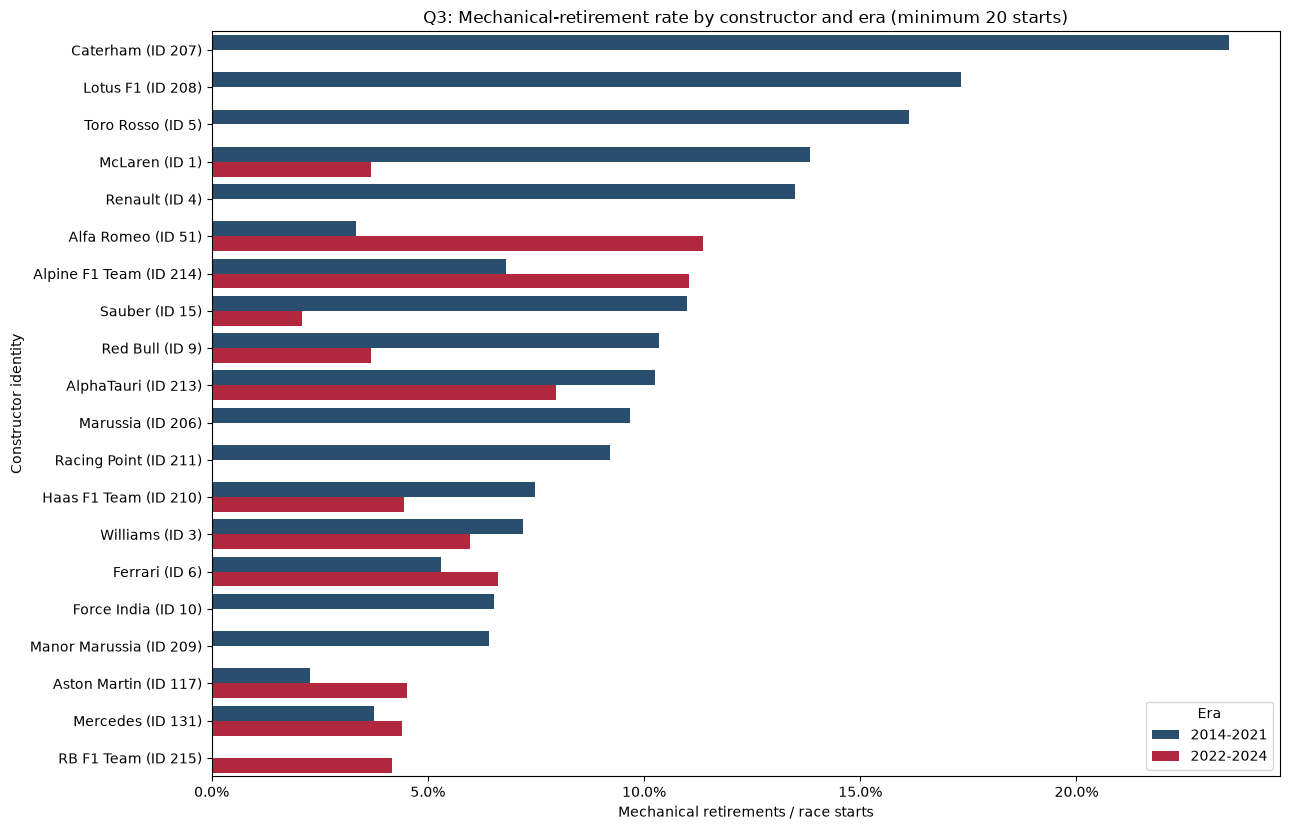

2014-2021: Caterham (ID 207) has the highest eligible rate at 23.5% (8/34).
2022-2024: Alfa Romeo (ID 51) has the highest eligible rate at 11.4% (10/88).
Limitation: status labels are coarse; the mapping is a transparent operational definition, not a full engineering failure diagnosis.


In [29]:
# Q3: constructor mechanical-retirement rates in two regulation eras
MECHANICAL_STATUSES = {
    'Engine', 'Gearbox', 'Transmission', 'Clutch', 'Hydraulics', 'Electrical', 'Radiator',
    'Suspension', 'Brakes', 'Differential', 'Overheating', 'Mechanical', 'Steering',
    'Driveshaft', 'Fuel pressure', 'Water pressure', 'Throttle', 'Electronics',
    'Exhaust', 'Oil leak', 'Water leak', 'Fuel pump', 'Track rod', 'Oil pressure',
    'Fuel system', 'Launch control', 'Power loss', 'Vibrations', 'Drivetrain', 'Ignition',
    'Chassis', 'Battery', 'Halfshaft', 'Crankshaft', 'Alternator', 'Oil pump', 'Fuel leak',
    'Injection', 'Distributor', 'Turbo', 'CV joint', 'Water pump', 'Spark plugs', 'Oil pipe',
    'Axle', 'Water pipe', 'Magneto', 'Supercharger', 'Power Unit', 'ERS', 'Brake duct',
    'Seat', 'Undertray', 'Cooling system'
}

q3 = (modeling_results
      .merge(cleaned_dfs['races'][['raceId', 'year']], on='raceId', how='left', validate='many_to_one')
      .merge(cleaned_dfs['constructors'][['constructorId', 'name']], on='constructorId', how='left', validate='many_to_one')
      .merge(cleaned_dfs['status'][['statusId', 'status']], on='statusId', how='left', validate='many_to_one'))
assert not q3.duplicated(['raceId', 'driverId']).any()
assert q3[['year', 'name', 'status']].notna().all().all(), 'A required Q3 join produced missing values.'
q3 = q3.loc[q3['year'].between(2014, 2024)].copy()
q3['era'] = np.where(q3['year'].le(2021), '2014-2021', '2022-2024')
AMBIGUOUS_COMPONENT_STATUSES = {'Tyre', 'Puncture', 'Wheel', 'Wheel rim', 'Wheel nut',
                               'Front wing', 'Rear wing'}
FINISHED_CLASSIFIED_PATTERN = r'^(Finished|\+\d+ Laps?)$'
q3['mechanical_retirement'] = q3['status'].isin(MECHANICAL_STATUSES)
q3['ambiguous_component_status'] = q3['status'].isin(AMBIGUOUS_COMPONENT_STATUSES)
q3['status_category'] = np.select(
    [q3['mechanical_retirement'], q3['status'].str.match(FINISHED_CLASSIFIED_PATTERN, na=False)],
    ['mechanical', 'finished/classified'],
    default='non_mechanical'
)
q3['constructor_label'] = q3['name'] + ' (ID ' + q3['constructorId'].astype(str) + ')'

q3_status_audit = (q3.groupby(['status_category', 'status'], as_index=False)
                   .agg(starts=('raceId', 'size'))
                   .sort_values(['status_category', 'starts'], ascending=[True, False]))
q3_status_audit['mapping_decision'] = np.select(
    [q3_status_audit['status_category'].eq('mechanical'),
     q3_status_audit['status_category'].eq('finished/classified'),
     q3_status_audit['status'].isin(AMBIGUOUS_COMPONENT_STATUSES)],
    ['Include: clear internal car-system failure',
     'Exclude from mechanical rate: finished/classified',
     'Exclude from primary rate: component label may reflect contact/debris damage'],
    default='Exclude from mechanical rate: non-mechanical, ambiguous, or external cause'
)
q3_category_summary = (q3.groupby('status_category', as_index=False)
                       .agg(race_starts=('raceId', 'size'))
                       .set_index('status_category')
                       .reindex(['mechanical', 'non_mechanical', 'finished/classified'], fill_value=0)
                       .reset_index())

q3_constructor_rates_all = (q3.groupby(['era', 'constructorId', 'constructor_label'], as_index=False)
                            .agg(race_starts=('mechanical_retirement', 'size'),
                                 mechanical_retires=('mechanical_retirement', 'sum')))
q3_constructor_rates_all['mechanical_retirement_rate'] = (
    q3_constructor_rates_all['mechanical_retires'] / q3_constructor_rates_all['race_starts']
)
q3_ambiguous_component_sensitivity = (q3.groupby(['era', 'constructorId', 'constructor_label'], as_index=False)
                                     .agg(race_starts=('raceId', 'size'),
                                          primary_mechanical_retires=('mechanical_retirement', 'sum'),
                                          ambiguous_component_statuses=('ambiguous_component_status', 'sum')))
q3_ambiguous_component_sensitivity['rate_including_ambiguous_components'] = (
    (q3_ambiguous_component_sensitivity['primary_mechanical_retires']
     + q3_ambiguous_component_sensitivity['ambiguous_component_statuses'])
    / q3_ambiguous_component_sensitivity['race_starts']
)
MIN_Q3_STARTS = 20
q3_constructor_ranking = (q3_constructor_rates_all.loc[lambda d: d['race_starts'] >= MIN_Q3_STARTS]
                          .sort_values(['era', 'mechanical_retirement_rate', 'race_starts'], ascending=[True, False, False])
                          .copy())
q3_constructor_ranking['rank_within_era'] = q3_constructor_ranking.groupby('era')['mechanical_retirement_rate'].rank(
    method='dense', ascending=False
).astype(int)

print(f'Q3 denominator: {len(q3):,} race starts in 2014-2024 after excluding confirmed non-starters.')
print(f'Mechanical-status mapping: {len(MECHANICAL_STATUSES)} explicitly included labels.')
print('Status-category counts:')
display(q3_category_summary)
print(f'Ranking rule: at least {MIN_Q3_STARTS} starts per constructor-era.')
display(q3_status_audit)
display(q3_ambiguous_component_sensitivity[['era', 'constructor_label', 'race_starts',
                                            'primary_mechanical_retires', 'ambiguous_component_statuses',
                                            'rate_including_ambiguous_components']])
display(q3_constructor_ranking[['era', 'rank_within_era', 'constructor_label', 'race_starts',
                                'mechanical_retires', 'mechanical_retirement_rate']])

q3_plot = q3_constructor_ranking.copy()
constructor_order = (q3_plot.groupby('constructor_label')['mechanical_retirement_rate'].max()
                     .sort_values(ascending=False).index)
plt.figure(figsize=(13, max(6, 0.42 * len(constructor_order))))
sns.barplot(data=q3_plot, y='constructor_label', x='mechanical_retirement_rate', hue='era',
            order=constructor_order, palette={'2014-2021': '#1f4e79', '2022-2024': '#c8102e'})
plt.gca().xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.title('Q3: Mechanical-retirement rate by constructor and era (minimum 20 starts)')
plt.xlabel('Mechanical retirements / race starts')
plt.ylabel('Constructor identity')
plt.legend(title='Era')
plt.tight_layout()
plt.show()

q3_leaders = (q3_constructor_ranking.sort_values(['era', 'mechanical_retirement_rate', 'race_starts'], ascending=[True, False, False])
              .groupby('era', as_index=False).first())
for _, row in q3_leaders.iterrows():
    print(f"{row['era']}: {row['constructor_label']} has the highest eligible rate at "
          f"{row['mechanical_retirement_rate']:.1%} ({int(row['mechanical_retires'])}/{int(row['race_starts'])}).")
print('Limitation: status labels are coarse; the mapping is a transparent operational definition, not a full engineering failure diagnosis.')


---
# 3. Historical feature engineering — Member 3

> **Member 3 status: READY FOR MODELING**
>
> **Output:** one leakage-safe row per `(raceId, driverId)` in `feature_df`, with pre-race grid, qualifying, form, and standings features.

> **Safety rule:** each historical feature uses earlier completed races only; post-race fields are excluded.

### 3.1 Build the driver–race base

Join race metadata onto the deduplicated results. The *target* comes from `positionOrder`, but `positionOrder` and every other current-race outcome are **never model inputs**. We preserve identifiers to make auditing and later joins straightforward.

In [30]:
from sklearn.model_selection import ParameterGrid

assert "cleaned_dfs" in globals() and "modeling_results" in globals(), (
    "Run the original Member 1 notebook cells first."
)

# Member 1 supplies the documented race-starter base; results_dedup remains the full audit table.
base = modeling_results.copy()
assert not base.duplicated(["raceId", "driverId"]).any()
assert base["positionOrder"].notna().all(), "Missing finishing order: target cannot be built safely."

race_metadata = cleaned_dfs["races"][["raceId", "year", "round", "date", "circuitId"]].copy()
assert race_metadata["raceId"].is_unique
base = base.merge(race_metadata, on="raceId", how="left", validate="many_to_one")
assert base[["year", "round", "date"]].notna().all().all(), "Missing race chronology after join."
base["year"] = pd.to_numeric(base["year"], errors="raise").astype(int)
base["round"] = pd.to_numeric(base["round"], errors="raise").astype(int)
base["date"] = pd.to_datetime(base["date"], errors="raise")
base["podium"] = (pd.to_numeric(base["positionOrder"], errors="raise") <= 3).astype(int)
base["grid"] = pd.to_numeric(base["grid"], errors="coerce")
base = base.sort_values(["year", "round", "date", "raceId", "driverId"]).reset_index(drop=True)
assert len(base) == len(modeling_results)
print("Base rows:", len(base), "| unique driver-race pairs:",
      base[["raceId", "driverId"]].drop_duplicates().shape[0])
print("Years:", base["year"].min(), "to", base["year"].max())
display(base[["raceId", "driverId", "constructorId", "year", "round", "grid", "podium"]].head())

ModuleNotFoundError: No module named 'sklearn'

### 3.2 Add qualifying features

Qualifying position can differ from the grid after penalties. Join qualifying using **both** driver and race IDs. Older seasons have incomplete qualifying data, so missing qualifying values remain missing for the later preprocessing stage. We also record whether qualifying data was available, rather than making up historical times.

In [ ]:
qual = cleaned_dfs["qualifying"].copy()
qual_cols = [c for c in ["raceId", "driverId", "position", "q1_sec", "q2_sec", "q3_sec"] if c in qual.columns]
qual = qual[qual_cols].copy()
qual["qualifying_position"] = pd.to_numeric(qual["position"], errors="coerce")
qual = qual.drop(columns=["position"])

# AUDIT: current data has zero duplicate qualifying driver-race keys; retain a defensive rule for new versions.
q_dup = int(qual.duplicated(["raceId", "driverId"]).sum())
print("Duplicated qualifying driver-race keys:", q_dup)
if q_dup:
    # TEMPORARY: Keep earliest source row; do not silently multiply model rows.
    qual = qual.drop_duplicates(["raceId", "driverId"], keep="first")

feature_df = base.merge(qual, on=["raceId", "driverId"], how="left", validate="one_to_one")
feature_df["qualifying_available"] = feature_df["qualifying_position"].notna().astype(int)
feature_df["grid_top3"] = feature_df["grid"].between(1, 3).astype(int)
feature_df["grid_top5"] = feature_df["grid"].between(1, 5).astype(int)

# LEAKAGE_CHECK: These qualifying and grid columns are pre-race; race finishing data is not.
assert len(feature_df) == len(base)
print("Qualifying-position availability: {:.1%}".format(feature_df["qualifying_available"].mean()))

Duplicated qualifying driver-race keys: 0
Qualifying-position availability: 41.7%


### 3.3 Add driver form from earlier races

We calculate past podium rates from previously completed races. `shift(1)` excludes the current row. For a driver with no history, the historical rate is left as missing; Member 4 will impute it using training-only statistics.

In [ ]:
feature_df = feature_df.sort_values(["year", "round", "date", "raceId", "driverId"]).copy()

# LEAKAGE_CHECK: Driver form calculations exclude the current race using shift(1).
driver_grp = feature_df.groupby("driverId", sort=False)
feature_df["driver_races_before"] = driver_grp.cumcount()
feature_df["driver_podium_rate_before"] = driver_grp["podium"].transform(
    lambda s: s.shift(1).expanding(min_periods=1).mean()
)
feature_df["driver_last5_podium_rate"] = driver_grp["podium"].transform(
    lambda s: s.shift(1).rolling(5, min_periods=1).mean()
)

# MODELING ASSUMPTION: the five-race window is a starting hypothesis; validate it later without using test data.
print(feature_df[["driverId", "year", "round", "driver_races_before",
                  "driver_last5_podium_rate"]].head(8).to_string(index=False))
assert feature_df.loc[feature_df["driver_races_before"].eq(0),
                      "driver_last5_podium_rate"].isna().all()

 driverId  year  round  driver_races_before  driver_last5_podium_rate
      579  1950      1                    0                       NaN
      589  1950      1                    0                       NaN
      619  1950      1                    0                       NaN
      627  1950      1                    0                       NaN
      640  1950      1                    0                       NaN
      642  1950      1                    0                       NaN
      660  1950      1                    0                       NaN
      661  1950      1                    0                       NaN


### 3.4 Add constructor form without teammate leakage

A team normally enters more than one driver in a race. We **first aggregate at constructor–race level**, then shift and roll over completed previous races. This prevents a teammate's result from the *same race* appearing as a pre-race feature.

In [ ]:
team_race = (feature_df.groupby(["constructorId", "raceId", "year", "round", "date"], as_index=False)
             .agg(team_podiums=("podium", "sum"), team_entries=("driverId", "nunique")))
team_race["team_podium_fraction"] = team_race["team_podiums"] / team_race["team_entries"]
team_race = team_race.sort_values(["year", "round", "date", "raceId", "constructorId"])
team_grp = team_race.groupby("constructorId", sort=False)
team_race["constructor_races_before"] = team_grp.cumcount()
team_race["constructor_last5_podium_rate"] = team_grp["team_podium_fraction"].transform(
    lambda s: s.shift(1).rolling(5, min_periods=1).mean()
)
team_race["constructor_podium_rate_before"] = team_grp["team_podium_fraction"].transform(
    lambda s: s.shift(1).expanding(min_periods=1).mean()
)
team_features = ["raceId", "constructorId", "constructor_races_before",
                 "constructor_last5_podium_rate", "constructor_podium_rate_before"]
feature_df = feature_df.merge(team_race[team_features],
                              on=["raceId", "constructorId"], how="left", validate="many_to_one")
# LEAKAGE_CHECK: Each teammate in the same constructor/race must get identical historical team form.
assert (feature_df.groupby(["raceId", "constructorId"])["constructor_last5_podium_rate"]
        .nunique(dropna=False) <= 1).all()
print("Constructor historical form created for", team_race["constructorId"].nunique(), "teams")

Constructor historical form created for 196 teams


### 3.5 Add standings before the current race

The standings CSVs contain **post-race** points and positions. We attach the latest earlier standings within the same season, using a backward as-of join with `allow_exact_matches=False`. This also handles drivers who skip races more reliably than a simple group shift on sparse standings rows. First-round known points default to zero; missing previous rank remains missing.

In [ ]:
def attach_prior_standings(frame, table, entity_key, prefix):
    """Attach the last known post-race standings from an earlier round of the same season."""
    standings = cleaned_dfs[table][["raceId", entity_key, "points", "position"]].copy()
    standings = standings.merge(
        race_metadata[["raceId", "year", "round"]], on="raceId", how="left", validate="many_to_one"
    )
    standings["points"] = pd.to_numeric(standings["points"], errors="coerce")
    standings["position"] = pd.to_numeric(standings["position"], errors="coerce")
    standings["year"] = pd.to_numeric(standings["year"], errors="coerce")
    standings["round"] = pd.to_numeric(standings["round"], errors="coerce")
    standings = standings.dropna(subset=[entity_key, "year", "round"])

    # AUDIT: current data has zero duplicate entity-race standings keys; retain a defensive rule for new versions.
    duplicates = int(standings.duplicated(["raceId", entity_key]).sum())
    print(f"{prefix} standings duplicate keys: {duplicates}")
    if duplicates:
        # TEMPORARY: Keep last entry; review if raw data contains unusual historical duplication.
        standings = standings.drop_duplicates(["raceId", entity_key], keep="last")

    left = frame[["raceId", entity_key, "year", "round"]].copy()
    left["__original_order"] = np.arange(len(left))
    left["__entity_year"] = left[entity_key].astype(str) + ":" + left["year"].astype(int).astype(str)
    standings["__entity_year"] = standings[entity_key].astype(str) + ":" + standings["year"].astype(int).astype(str)

    # LEAKAGE_CHECK: backward join excludes the *same* round and all future rounds.
    left_sorted = left.sort_values("round")
    right_sorted = standings[["__entity_year", "round", "points", "position"]].sort_values("round")
    joined = pd.merge_asof(
        left_sorted, right_sorted, on="round", by="__entity_year",
        direction="backward", allow_exact_matches=False
    ).sort_values("__original_order")
    assert np.array_equal(joined["__original_order"].to_numpy(), np.arange(len(frame)))
    assert len(joined) == len(frame)
    return (joined["points"].fillna(0).to_numpy(dtype=float),
            joined["position"].to_numpy(dtype=float))

feature_df["driver_points_before_race"], feature_df["driver_rank_before_race"] = (
    attach_prior_standings(feature_df, "driver_standings", "driverId", "driver")
)
feature_df["constructor_points_before_race"], feature_df["constructor_rank_before_race"] = (
    attach_prior_standings(feature_df, "constructor_standings", "constructorId", "constructor")
)
print("Pre-race standings attached. Example:")
display(feature_df[["year", "round", "driverId", "driver_points_before_race",
                    "constructor_points_before_race"]].tail(8))

driver standings duplicate keys: 0
constructor standings duplicate keys: 0
Pre-race standings attached. Example:


,year,round,driverId,driver_points_before_race,constructor_points_before_race
25059,2024,24,847,235.0,446.0
25060,2024,24,848,12.0,17.0
25061,2024,24,852,30.0,46.0
25062,2024,24,855,4.0,4.0
25063,2024,24,857,291.0,640.0
25064,2024,24,859,4.0,46.0
25065,2024,24,861,5.0,17.0
25066,2024,24,862,0.0,59.0


### 3.6 Validate features and define the candidate baseline

Check the one-row-per-driver-race contract and missingness. The baseline below uses only valid pre-race information; its EDA evidence appears in Section 4.1.1.

In [ ]:
# Final compact baseline: every column is known before the race and has a documented rationale.
numeric_features = [
    "grid", "qualifying_position", "qualifying_available",
    "driver_races_before", "driver_podium_rate_before", "driver_last5_podium_rate",
    "constructor_races_before", "constructor_podium_rate_before",
    "constructor_last5_podium_rate", "driver_rank_before_race",
    "constructor_rank_before_race"
]
# Identifiers are held back from the baseline to avoid unnecessary memorisation.
categorical_features = []
optional_feature_groups = {
    "derived_grid_flags": ["grid_top3", "grid_top5"],
    "standings_points_instead_of_rank": ["driver_points_before_race", "constructor_points_before_race"],
    "categorical_context": ["circuitId", "constructorId"],
}
selected_features = numeric_features + categorical_features

# LEAKAGE_CHECK: Explicitly exclude current result fields from features.
for forbidden in ["podium", "positionOrder", "points", "statusId", "laps", "milliseconds",
                  "fastestLap", "fastestLapTime", "fastestLapSpeed", "resultId"]:
    assert forbidden not in selected_features, f"Forbidden input: {forbidden}"
assert feature_df[["raceId", "driverId"]].notna().all().all()
assert not feature_df.duplicated(["raceId", "driverId"]).any()
assert len(feature_df) == len(modeling_results)
assert feature_df["podium"].isin([0, 1]).all()
assert set(selected_features).issubset(feature_df.columns)
print("Validated rows:", len(feature_df), "| Candidate inputs:", len(selected_features))
display((feature_df[selected_features].isna().mean() * 100)
        .sort_values(ascending=False).head(12).rename("Missing percentage").to_frame())

# REVIEW_INTEGRATION: Test optional_feature_groups only on validation during later ablations.

Validated rows: 25067 | Candidate inputs: 11


,Missing percentage
qualifying_position,58.291778
constructor_rank_before_race,13.152751
driver_rank_before_race,13.148761
driver_podium_rate_before,3.147565
driver_last5_podium_rate,3.147565
constructor_last5_podium_rate,1.252643
constructor_podium_rate_before,1.252643
qualifying_available,0.000000
grid,0.000000
constructor_races_before,0.000000


---
# 4. Choose features, split time, and preprocess — Member 4

> **Member 4 status: READY FOR MODELING**
>
> **Output:** a documented 11-feature baseline and model-ready train/validation/test matrices. All preprocessing is fitted on training data only.

### 4.1 Chronological train / validation / test split

Train on **1950–2017**, validate on **2018–2021**, and reserve **2022–2024** for the untouched final test set. This gives a larger validation period while preserving the newest regulation era as a realistic future-race test. No random splitting is used; all drivers from one race remain in the same split.

In [ ]:
# Fixed chronological boundary: decide it before modeling and do not change it using test results.
train_df = feature_df.loc[feature_df["year"] <= 2017].copy()
val_df = feature_df.loc[feature_df["year"].between(2018, 2021)].copy()
test_df = feature_df.loc[feature_df["year"] >= 2022].copy()
assert all(len(d) > 0 for d in [train_df, val_df, test_df]), "One temporal split is empty. Check data coverage."
assert set(train_df["raceId"]).isdisjoint(set(val_df["raceId"]))
assert set(val_df["raceId"]).isdisjoint(set(test_df["raceId"]))
assert set(train_df["raceId"]).isdisjoint(set(test_df["raceId"]))

X_train, y_train = train_df[selected_features].copy(), train_df["podium"].astype(int).copy()
X_val, y_val = val_df[selected_features].copy(), val_df["podium"].astype(int).copy()
X_test, y_test = test_df[selected_features].copy(), test_df["podium"].astype(int).copy()

split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Rows": [len(train_df), len(val_df), len(test_df)],
    "Min year": [x["year"].min() for x in [train_df, val_df, test_df]],
    "Max year": [x["year"].max() for x in [train_df, val_df, test_df]],
    "Podium rate": [y_train.mean(), y_val.mean(), y_test.mean()]
})
display(split_summary)

,Split,Rows,Min year,Max year,Podium rate
0,Train,22095,1950,2017,0.133424
1,Validation,1618,2018,2021,0.150185
2,Test,1354,2022,2024,0.150665


### 4.1.1 Training-only feature evidence

These visuals use `train_df` only. They support feature selection without inspecting the untouched test period. The scatter matrix is an overview of a small set of key numeric inputs; the heatmap highlights redundancy; and the binned plots show descriptive podium-rate patterns with sample sizes. They are evidence for hypotheses, not proof of causation or final model importance.

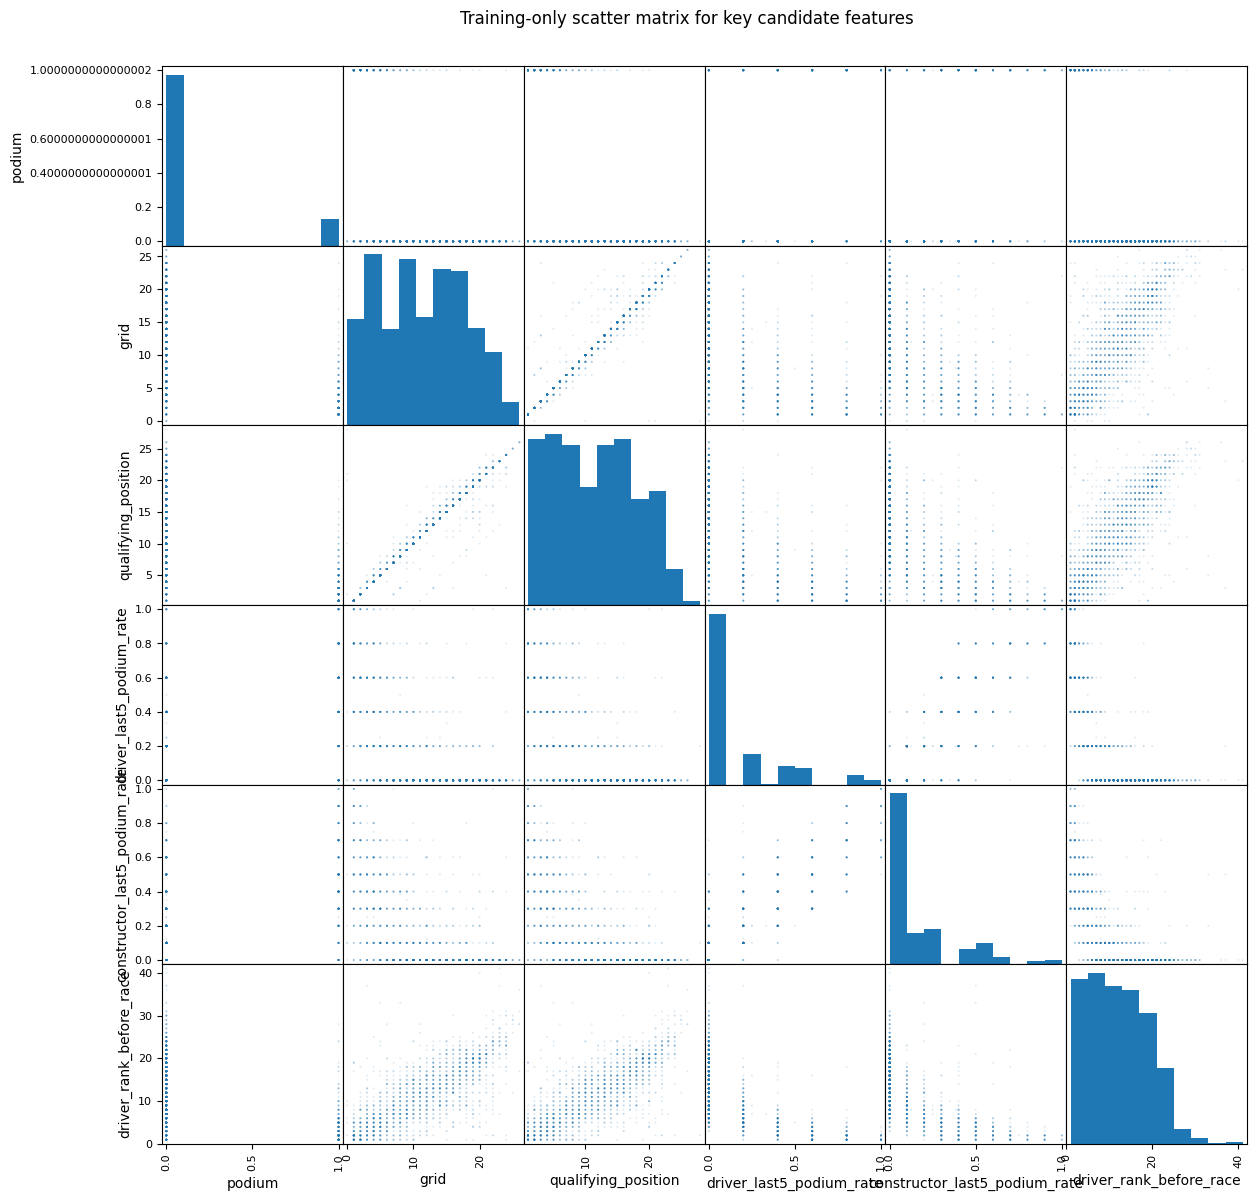

Scatter-matrix rows: 2,000 sampled from 6,691 complete training rows.


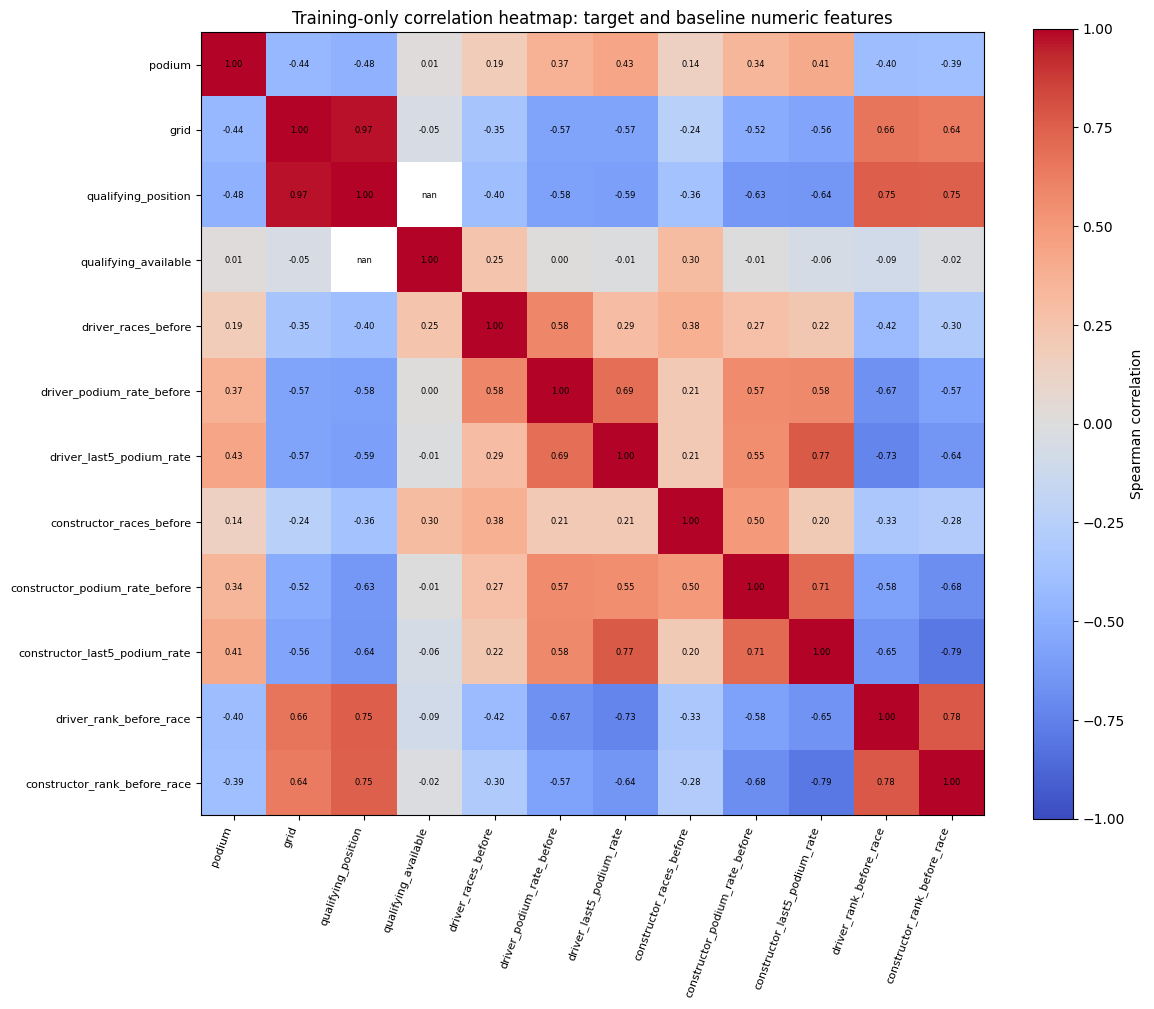

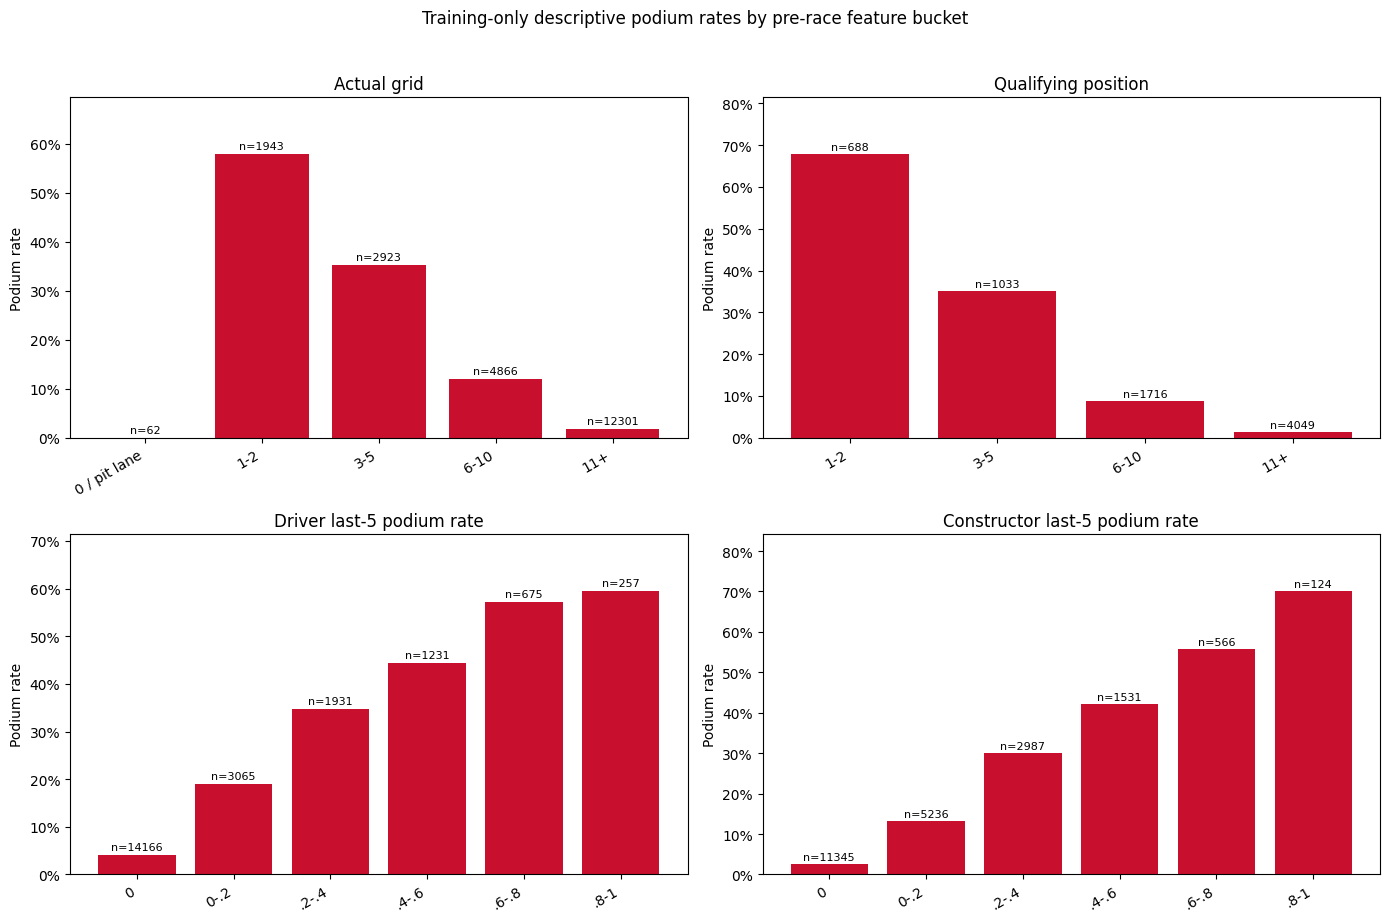

In [ ]:
from pandas.plotting import scatter_matrix

# A compact matrix is readable; identifiers and binary grid flags are intentionally omitted.
scatter_cols = [
    "podium", "grid", "qualifying_position",
    "driver_last5_podium_rate", "constructor_last5_podium_rate",
    "driver_rank_before_race",
]
scatter_source = train_df[scatter_cols].dropna().copy()
assert not scatter_source.empty, "No complete training rows are available for the scatter matrix."
scatter_sample = scatter_source.sample(n=min(2_000, len(scatter_source)), random_state=42)
scatter_matrix(scatter_sample, figsize=(14, 14), alpha=0.15, diagonal="hist", marker=".", s=8)
plt.suptitle("Training-only scatter matrix for key candidate features", y=0.92)
plt.show()
print(f"Scatter-matrix rows: {len(scatter_sample):,} sampled from {len(scatter_source):,} complete training rows.")

# Spearman correlation is appropriate for ranks, rates, and monotonic relationships.
correlation_cols = ["podium"] + numeric_features
spearman_corr = train_df[correlation_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10))
image = ax.imshow(spearman_corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(np.arange(len(correlation_cols)), correlation_cols, rotation=70, ha="right", fontsize=8)
ax.set_yticks(np.arange(len(correlation_cols)), correlation_cols, fontsize=8)
for row in range(len(correlation_cols)):
    for col in range(len(correlation_cols)):
        ax.text(col, row, f"{spearman_corr.iloc[row, col]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(image, ax=ax, label="Spearman correlation")
ax.set_title("Training-only correlation heatmap: target and baseline numeric features")
plt.tight_layout()
plt.show()

# Descriptive podium rates by interpretable pre-race buckets, with group sizes visible.
plot_specs = [
    ("grid", [-0.5, 0.5, 2.5, 5.5, 10.5, np.inf], ["0 / pit lane", "1-2", "3-5", "6-10", "11+"], "Actual grid"),
    ("qualifying_position", [0.5, 2.5, 5.5, 10.5, np.inf], ["1-2", "3-5", "6-10", "11+"], "Qualifying position"),
    ("driver_last5_podium_rate", [-0.001, 0.0, 0.2, 0.4, 0.6, 0.8, 1.0], ["0", "0-.2", ".2-.4", ".4-.6", ".6-.8", ".8-1"], "Driver last-5 podium rate"),
    ("constructor_last5_podium_rate", [-0.001, 0.0, 0.2, 0.4, 0.6, 0.8, 1.0], ["0", "0-.2", ".2-.4", ".4-.6", ".6-.8", ".8-1"], "Constructor last-5 podium rate"),
]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (feature, bins, labels, title) in zip(axes.ravel(), plot_specs):
    plot_data = train_df[[feature, "podium"]].dropna().copy()
    plot_data["bucket"] = pd.cut(plot_data[feature], bins=bins, labels=labels, include_lowest=True)
    summary = plot_data.groupby("bucket", observed=False)["podium"].agg(["mean", "size"])
    positions = np.arange(len(summary))
    ax.bar(positions, summary["mean"], color="#c8102e")
    ax.set_xticks(positions, summary.index.astype(str), rotation=30, ha="right")
    ax.set_ylim(0, min(1, max(0.15, summary["mean"].max() * 1.2)))
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.set_title(title)
    ax.set_ylabel("Podium rate")
    for pos, (_, row) in enumerate(summary.iterrows()):
        ax.text(pos, row["mean"] + 0.01, f"n={int(row['size'])}", ha="center", fontsize=8)
fig.suptitle("Training-only descriptive podium rates by pre-race feature bucket", y=1.02)
plt.tight_layout()
plt.show()


### 4.1.2 Final baseline feature decisions

The first model uses 11 numeric pre-race features. `grid` and `qualifying_position` capture starting position and qualifying pace; `qualifying_available` preserves historical missingness rather than inventing a time. Driver and constructor race counts plus long-term and last-5 podium rates represent experience, established performance, and recent form using only earlier races. Driver and constructor **rank** before the race represent current-season competitiveness and are preferred to raw points because F1 scoring systems changed across the historical period.

The decision table below links every baseline and excluded feature group to the training-only EDA in Section 4.1.1. Correlations are Spearman correlations with `podium`; binned plots show descriptive podium rates, not causal effects.

| Decision | Feature(s) | Evidence and rationale |
|---|---|---|
| **Keep** | `grid`, `qualifying_position` | The binned plots show podium rates falling sharply as grid/qualifying position worsens. Their correlations with `podium` are −0.44 and −0.48. Both are valid after-qualifying, pre-race inputs, even though they are strongly related to each other (0.97). |
| **Keep** | `qualifying_available` | This is not a performance signal (correlation 0.01). It records whether `qualifying_position` was genuinely observed, so median-imputed historical qualifying values are not confused with real results. |
| **Keep** | Driver/constructor long-term and last-5 podium rates | The binned plots rise consistently with recent form. Correlations with `podium` are +0.37/+0.43 for driver long-term/last-5 form and +0.34/+0.41 for constructor form. All are calculated from earlier races only. |
| **Keep** | `driver_races_before`, `constructor_races_before` | These have weaker positive correlations (+0.19 and +0.14), but provide pre-race experience/context and help distinguish a zero historical rate from a rate based on very few prior races. |
| **Keep** | `driver_rank_before_race`, `constructor_rank_before_race` | These represent current-season competitiveness using earlier rounds only; their correlations with `podium` are −0.40 and −0.39. Ranks are preferred to raw points because scoring systems differ across eras. |
| **Do not use in baseline** | `grid_top3`, `grid_top5` | They are deterministic versions of `grid`, so they add no new information to the first model. |
| **Do not use in baseline** | `driver_points_before_race`, `constructor_points_before_race` | They overlap with the chosen standings ranks and are less comparable across historical scoring systems. |
| **Do not use in baseline** | `driverId`, `constructorId`, `circuitId` | Identity variables can let a one-hot model memorise historical teams, drivers, or tracks rather than learn pre-race signals. They are held out as optional context, not treated as baseline predictors. |
| **Never use as features** | Current-race `positionOrder`, points, status, laps, time, fastest-lap and result fields | These are known only after the race and would leak the answer. |

Optional held-out columns remain in `feature_df` for clearly labelled later comparisons. The test set is not used for any feature decision.

### 4.2 Fit preprocessing on training data only

Baseline numerical fields use median imputation + standard scaling. The compact baseline deliberately has no categorical identifiers; optional circuit/constructor identifiers can later be added in a separate validation-only ablation with most-frequent imputation and one-hot encoding. Missing prior history is handled by the learned imputer rather than pretending first-time drivers have known performance. Tree models can later reuse unscaled features via a separate pipeline if justified.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Optional circuit/team categories are deliberately held back for later validation-only ablation.
# LEAKAGE_CHECK: .fit_transform is applied only to training observations.
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
transformers = [("num", num_pipeline, numeric_features)]
if categorical_features:
    transformers.append(("cat", cat_pipeline, categorical_features))
preprocessor = ColumnTransformer(transformers, remainder="drop", sparse_threshold=0.3)

Xtr_sc = preprocessor.fit_transform(X_train)
Xva_sc = preprocessor.transform(X_val)
Xte_sc = preprocessor.transform(X_test)
model_feature_names = preprocessor.get_feature_names_out()
assert Xtr_sc.shape[1] == Xva_sc.shape[1] == Xte_sc.shape[1]
assert np.isfinite(Xtr_sc.data if hasattr(Xtr_sc, "toarray") else Xtr_sc).all()
assert np.isfinite(Xva_sc.data if hasattr(Xva_sc, "toarray") else Xva_sc).all()
assert np.isfinite(Xte_sc.data if hasattr(Xte_sc, "toarray") else Xte_sc).all()
print("Model-ready matrices:", Xtr_sc.shape, Xva_sc.shape, Xte_sc.shape)
print("First 12 processed features:", list(model_feature_names[:12]))

Model-ready matrices: (22095, 11) (1618, 11) (1354, 11)
First 12 processed features: ['num__grid', 'num__qualifying_position', 'num__qualifying_available', 'num__driver_races_before', 'num__driver_podium_rate_before', 'num__driver_last5_podium_rate', 'num__constructor_races_before', 'num__constructor_podium_rate_before', 'num__constructor_last5_podium_rate', 'num__driver_rank_before_race', 'num__constructor_rank_before_race']


### 4.3 Check the processed data

Compare missingness and the range of a selected numerical feature before vs after processing. This visualizes the effect of an actual step, as required in the milestone.

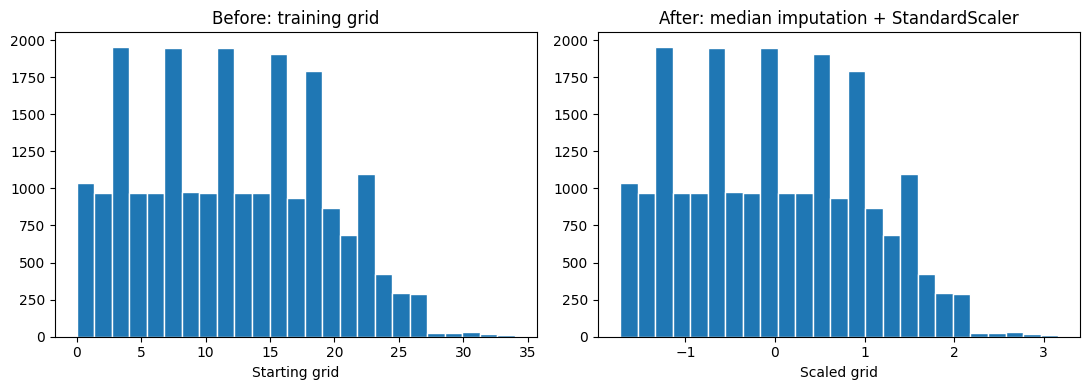

Grid missing before: 0 | Missing after: 0
Scaled train mean / std: -0.0 1.0


In [ ]:
from scipy import sparse

chosen = "grid"
raw_grid = pd.to_numeric(X_train[chosen], errors="coerce")
processed_grid = Xtr_sc[:, numeric_features.index(chosen)]
if sparse.issparse(processed_grid):
    processed_grid = processed_grid.toarray()
processed_grid = np.asarray(processed_grid).ravel()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(raw_grid.dropna(), bins=25, edgecolor="white")
axes[0].set_title("Before: training grid")
axes[0].set_xlabel("Starting grid")
axes[1].hist(processed_grid, bins=25, edgecolor="white")
axes[1].set_title("After: median imputation + StandardScaler")
axes[1].set_xlabel("Scaled grid")
plt.tight_layout()
plt.show()
print("Grid missing before:", int(raw_grid.isna().sum()),
      "| Missing after:", int(pd.isna(processed_grid).sum()))
print("Scaled train mean / std:", round(processed_grid.mean(), 4), round(processed_grid.std(), 4))

### 4.4 Compare preprocessing order on validation data

The milestone asks for at least two **order** experiments. We evaluate these without ever looking at test performance:

1. **Clipping vs mean imputation:** clip outliers *then* mean-impute, versus mean-impute *then* clip.
2. **Log transform vs mean imputation:** log-transform points *then* mean-impute, versus mean-impute *then* log-transform.

To isolate order, both approaches in each experiment use the same train/validation rows, a common numerical feature set, standard scaling, and logistic regression. These experiments are informative diagnostics, **not** a claim that the variations improve the eventual neural network. Some data distributions can yield tied results; ties are still reportable.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

experiment_cols = ["grid", "qualifying_position", "driver_last5_podium_rate",
                   "constructor_last5_podium_rate", "driver_points_before_race",
                   "constructor_points_before_race"]
# These controlled order experiments use a fixed raw candidate slice; points are not baseline inputs.
exp_train = train_df[experiment_cols].apply(pd.to_numeric, errors="coerce")
exp_val = val_df[experiment_cols].apply(pd.to_numeric, errors="coerce")

# LEAKAGE_CHECK: All learned cutoffs, means and scalers come solely from exp_train.
def prepare_experiment(train_x, val_x, method):
    a = train_x.copy().astype(float)
    b = val_x.copy().astype(float)
    if method in ("clip_then_impute", "impute_then_clip"):
        low, high = a.quantile(.01), a.quantile(.99)
        mean = a.mean()
        if method == "clip_then_impute":
            a, b = a.clip(lower=low, upper=high, axis=1), b.clip(lower=low, upper=high, axis=1)
            fill = a.mean()
            a, b = a.fillna(fill), b.fillna(fill)
        else:
            a, b = a.fillna(mean), b.fillna(mean)
            a, b = a.clip(lower=low, upper=high, axis=1), b.clip(lower=low, upper=high, axis=1)
    elif method in ("log_then_impute", "impute_then_log"):
        # Count/points features are nonnegative. log1p is monotonic but mean() is nonlinear under it.
        point_cols = ["driver_points_before_race", "constructor_points_before_race"]
        assert (a[point_cols].dropna() >= 0).all().all()
        assert (b[point_cols].dropna() >= 0).all().all()
        if method == "log_then_impute":
            a[point_cols], b[point_cols] = np.log1p(a[point_cols]), np.log1p(b[point_cols])
            fill = a.mean()
            a, b = a.fillna(fill), b.fillna(fill)
        else:
            fill = a.mean()
            a, b = a.fillna(fill), b.fillna(fill)
            a[point_cols], b[point_cols] = np.log1p(a[point_cols]), np.log1p(b[point_cols])
    else:
        raise ValueError("Unknown experimental pipeline")
    # Protect against an all-missing training column if the dataset/version changes.
    assert a.notna().all().all() and b.notna().all().all(), "Experiment has all-missing columns."
    scaler = StandardScaler()
    return scaler.fit_transform(a), scaler.transform(b)

experiment_records = []
for experiment_name, methods in [
    ("1 · outlier/mean-imputation order", ["clip_then_impute", "impute_then_clip"]),
    ("2 · log/mean-imputation order", ["log_then_impute", "impute_then_log"])
]:
    for method in methods:
        xt, xv = prepare_experiment(exp_train, exp_val, method)
        baseline = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
        baseline.fit(xt, y_train)
        val_proba = baseline.predict_proba(xv)[:, 1]
        experiment_records.append({
            "Experiment": experiment_name,
            "Preprocessing order": method,
            "Validation PR-AUC": average_precision_score(y_val, val_proba),
            "Validation ROC-AUC": roc_auc_score(y_val, val_proba),
        })
experiment_results = pd.DataFrame(experiment_records)
display(experiment_results.round(4))
for experiment_name, group in experiment_results.groupby("Experiment", sort=False):
    best = group.sort_values(["Validation PR-AUC", "Validation ROC-AUC"], ascending=False).iloc[0]
    spread = group["Validation PR-AUC"].max() - group["Validation PR-AUC"].min()
    print(f"{experiment_name}: best validation order is {best['Preprocessing order']} "
          f"(PR-AUC={best['Validation PR-AUC']:.4f}); PR-AUC spread={spread:.4f}.")

# REVIEW_INTEGRATION: Re-run experiments if final features or season boundaries change.
# LEAKAGE_CHECK: Test set was not used in these comparisons.

,Experiment,Preprocessing order,Validation PR-AUC,Validation ROC-AUC
0,1 · outlier/mean-imputation order,clip_then_impute,0.6732,0.9226
1,1 · outlier/mean-imputation order,impute_then_clip,0.6732,0.9226
2,2 · log/mean-imputation order,log_then_impute,0.6723,0.9216
3,2 · log/mean-imputation order,impute_then_log,0.6723,0.9216


1 · outlier/mean-imputation order: best validation order is clip_then_impute (PR-AUC=0.6732); PR-AUC spread=0.0000.
2 · log/mean-imputation order: best validation order is log_then_impute (PR-AUC=0.6723); PR-AUC spread=0.0000.


### 4.5 Final checks and hand-off to modeling

**Ready for modeling:** `Xtr_sc`, `Xva_sc`, `Xte_sc`, `y_train`, `y_val`, `y_test`, and `preprocessor`. Modeling, XAI, and inference examples are the next phase.

In [ ]:
assert len(X_train) == len(y_train) == Xtr_sc.shape[0]
assert len(X_val) == len(y_val) == Xva_sc.shape[0]
assert len(X_test) == len(y_test) == Xte_sc.shape[0]
assert set(y_train.unique()).issubset({0, 1})
assert set(y_val.unique()).issubset({0, 1})
assert set(y_test.unique()).issubset({0, 1})
assert not feature_df.duplicated(["raceId", "driverId"]).any()
assert not set(selected_features).intersection({"podium", "positionOrder", "points", "laps", "statusId"})
print("[PASS] Members 3 & 4 feature engineering / preprocessing checks")
print("[PASS] Train-only preprocessing; separate validation and unseen test")
print("[PASS] Two preprocessing-order experiments on validation only")
print("[PASS] Baseline feature rationale and training-only selection visuals are documented")
print("Next: two statistical models + shallow NN, ablation, XAI, inference, report")

[PASS] Members 3 & 4 feature engineering / preprocessing checks
[PASS] Train-only preprocessing; separate validation and unseen test
[PASS] Two preprocessing-order experiments on validation only
[PASS] Baseline feature rationale and training-only selection visuals are documented
Next: two statistical models + shallow NN, ablation, XAI, inference, report
